# 💳 Cost-Sensitive & Explainable Machine Learning for Financial Risk
## Dual-Domain Benchmark: Credit Card Fraud & Loan Default Prediction
**Course:** CSE431: Machine Learning &bull; **Group:** Group 08 &bull; **Institution:** Department of Computer Science and Engineering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ShoumikBalaSomu/ML-Project-Group-08/blob/main/FinRisk_ML_Group08.ipynb)
[![GitHub Repository](https://img.shields.io/badge/GitHub-Repository-181717?logo=github)](https://github.com/ShoumikBalaSomu/ML-Project-Group-08)
[![Course](https://img.shields.io/badge/Course-CSE431%20Machine%20Learning-blue.svg)](https://github.com/ShoumikBalaSomu/ML-Project-Group-08)
[![License: CC0-1.0](https://img.shields.io/badge/License-CC0_1.0-lightgrey.svg)](https://creativecommons.org/publicdomain/zero/1.0/)

---

### 👥 Research Team & Equal Collaboration Statement
All team members contributed equally (33.3% each) across problem formulation, data pipeline design, model benchmarking, threshold optimization, XAI regulatory compliance, and report generation:
1. **Shoumik Bala Somu** (`shoumik.bala@gmail.com`) &bull; *Equal Co-Author (33.3%)*
2. **Md Israfil Hossen** &bull; *Equal Co-Author (33.3%)*
3. **Ariyan Islam Hridoy** &bull; *Equal Co-Author (33.3%)*

---

### 📋 Interactive Table of Contents
1. [Google Colab & Environment Setup](#section-1)
2. [Problem Motivation & Cost-Matrix Mathematics](#section-2)
3. [Cost Matrix & Empirical Threshold Optimization Engine](#section-3)
4. [Data Ingestion & Leakage-Free Preprocessing Pipelines](#section-4)
5. [Exploratory Data Analysis (EDA) & Imbalance Profiling](#section-5)
6. [Machine Learning Model Zoo Architecture](#section-6)
7. [Model Training & Threshold Sweeps (Task A: Credit Card Fraud)](#section-7)
8. [Model Training & Threshold Sweeps (Task B: Loan Default)](#section-8)
9. [Comparative Benchmarks & Cost Reduction Analysis](#section-9)
10. [Real-Time Production SLA & Latency Profiling](#section-10)
11. [Global Explainability via TreeSHAP](#section-11)
12. [Local Contrastive Explainability & Regulatory Compliance (5 Case Studies)](#section-12)
13. [Interactive What-If Cost & Volume Simulator](#section-13)
14. [Algorithmic Fairness (4/5ths Rule) & Model Drift Monitoring (PSI)](#section-14)
15. [Academic Citations & Reproducibility Statement](#section-15)


In [1]:
import sys
import time
import warnings
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import kagglehub
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set global deterministic random seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 120
sns.set_palette("tab10")
warnings.filterwarnings("ignore")

# Colab environment validation
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
    print("🚀 Running in Google Colab environment.")
except ImportError:
    IN_COLAB = False
    print("💻 Running in local / server environment.")

print(f"✅ Environment initialized on Python {sys.version.split()[0]}")
print("✅ Scikit-Learn pipelines, imputation, estimators, and metrics loaded successfully!")


/home/krishna/Projects/ML-Project-Group-08/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


💻 Running in local / server environment.
✅ Environment initialized on Python 3.14.6
✅ Scikit-Learn pipelines, imputation, estimators, and metrics loaded successfully!


<a id="section-2"></a>
## 2. Problem Motivation & Cost-Matrix Mathematics

### 2.1 The Asymmetric Cost Problem in Financial Risk
In financial risk systems, standard classification accuracy is misleading and operationally hazardous due to:
1. **Extreme Class Imbalance:** Fraud prevalence is $\sim 0.58\%$; loan default prevalence is $\sim 12.30\%$. A trivial baseline predicting the majority class achieves $99.42\%$ accuracy while failing to detect all financial crimes.
2. **Asymmetric Error Costs:** 
   - A **False Negative (FN)** (missing a stolen card transaction or defaulting borrower) causes catastrophic direct capital loss ($C_{\text{FN}} = \$400$ for fraud, $C_{\text{FN}} = \$5,000$ write-off for loans).
   - A **False Positive (FP)** (declining a legitimate cardholder or loan applicant) causes minor operational verification overhead ($C_{\text{FP}} = \$10$ for fraud review, $C_{\text{FP}} = \$500$ manual underwriting cost).
   - The cost ratio is **40:1** for credit card fraud and **10:1** for loan defaults.

### 2.2 Mathematical Formulation
Total financial loss $\mathcal{L}(p)$ under decision cutoff threshold $p$ is given by:

$$\mathcal{L}(p) = C_{\text{FN}} \cdot \text{FN}(p) + C_{\text{FP}} \cdot \text{FP}(p) + C_{\text{TP}} \cdot \text{TP}(p) + C_{\text{TN}} \cdot \text{TN}(p)$$

By Bayesian decision theory, the theoretical cost-optimal cutoff probability $p^*$ satisfies:

$$p^* = \frac{C_{\text{FP}} - C_{\text{TN}}}{(C_{\text{FP}} - C_{\text{TN}}) + (C_{\text{FN}} - C_{\text{TP}})}$$

For zero-cost correct decisions ($C_{\text{TN}} = C_{\text{TP}} = 0$):

$$p^* = \frac{C_{\text{FP}}}{C_{\text{FP}} + C_{\text{FN}}}$$

- **Task A (Fraud):** $p^* = \frac{10}{10 + 400} = \frac{10}{410} \approx 0.0244$
- **Task B (Loan):** $p^* = \frac{500}{500 + 5000} = \frac{500}{5500} \approx 0.0909$

Using the naive default threshold $p = 0.50$ leaves severe financial losses unmitigated. We optimize thresholds empirically on training folds to prevent test set lookahead leakage.


<a id="section-3"></a>
## 3. Cost Matrix & Empirical Threshold Optimization Engine

We implement vectorized implementations of `CostMatrix` and `ThresholdOptimizer` to calculate exact financial outcomes and sweep over 150 cutoff thresholds.


In [2]:
class CostMatrix:
    """Cost matrix specification for asymmetric binary decision tasks."""
    def __init__(self, cost_fn: float, cost_fp: float, cost_tp: float = 0.0, cost_tn: float = 0.0):
        self.cost_fn = float(cost_fn)
        self.cost_fp = float(cost_fp)
        self.cost_tp = float(cost_tp)
        self.cost_tn = float(cost_tn)

    def compute_total_cost(self, y_true: np.ndarray, y_pred: np.ndarray) -> float:
        """Compute total financial loss: C_fn*FN + C_fp*FP + C_tp*TP + C_tn*TN"""
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        return float(self.cost_fn * fn + self.cost_fp * fp + self.cost_tp * tp + self.cost_tn * tn)

    def compute_normalized_cost(self, y_true: np.ndarray, y_pred: np.ndarray) -> float:
        """Expected cost per processed customer transaction/application."""
        return self.compute_total_cost(y_true, y_pred) / max(1, len(y_true))


class ThresholdOptimizer:
    """Finds optimal decision threshold p* minimizing total expected financial loss."""
    def __init__(self, cost_matrix: CostMatrix, n_thresholds: int = 200):
        self.cost_matrix = cost_matrix
        self.n_thresholds = n_thresholds
        self.optimal_threshold_ = 0.5
        self.min_cost_ = float("inf")
        self.thresholds_ = np.linspace(0.01, 0.99, n_thresholds)
        self.cost_curve_ = []

    def fit(self, y_true: np.ndarray, y_proba: np.ndarray) -> "ThresholdOptimizer":
        best_thresh = 0.5
        best_cost = float("inf")
        self.cost_curve_ = []

        for thresh in self.thresholds_:
            y_pred = (y_proba >= thresh).astype(int)
            cost = self.cost_matrix.compute_total_cost(y_true, y_pred)
            self.cost_curve_.append(cost)
            if cost < best_cost:
                best_cost = cost
                best_thresh = thresh

        self.optimal_threshold_ = float(best_thresh)
        self.min_cost_ = float(best_cost)
        return self

    def predict(self, y_proba: np.ndarray) -> np.ndarray:
        return (y_proba >= self.optimal_threshold_).astype(int)

# Initialize production cost specifications
fraud_cost_matrix = CostMatrix(cost_fn=400.0, cost_fp=10.0, cost_tp=0.0, cost_tn=0.0)
loan_cost_matrix = CostMatrix(cost_fn=5000.0, cost_fp=500.0, cost_tp=0.0, cost_tn=0.0)

print(f"Task A (Fraud) Loss Ratio: {fraud_cost_matrix.cost_fn / fraud_cost_matrix.cost_fp:.0f}:1 ($400 FN vs $10 FP)")
print(f"Task B (Loan)  Loss Ratio: {loan_cost_matrix.cost_fn / loan_cost_matrix.cost_fp:.0f}:1 ($5,000 FN vs $500 FP)")


Task A (Fraud) Loss Ratio: 40:1 ($400 FN vs $10 FP)
Task B (Loan)  Loss Ratio: 10:1 ($5,000 FN vs $500 FP)


<a id="section-4"></a>
## 4. Data Ingestion, Cleaning & Scikit-Learn Preprocessing Pipelines

### 4.1 Strict Protection Against Data Leakage
1. **Chronological Splitting (Task A):** Credit card fraud patterns drift dynamically over time. Random k-fold cross-validation allows models to memorize future merchant fraud patterns to predict the past. We enforce strict temporal indexing: transactions from **2019** form the training split; transactions from **2020** form the true out-of-time test holdout.
2. **Leakage-Free Feature Transformers:** All scaling (`StandardScaler`), imputation (`SimpleImputer`), and categorical encoding (`OneHotEncoder`) parameters are strictly fitted **only** on training data, then applied immutably to the test holdout.
3. **Haversine Distance Formulation:** Spherical distance between customer location $(\text{lat}_1, \text{long}_1)$ and merchant coordinates $(\text{lat}_2, \text{long}_2)$:

$$d = 2 R \arcsin\left(\sqrt{\sin^2\left(\frac{\Delta\phi}{2}\right) + \cos\phi_1 \cos\phi_2 \sin^2\left(\frac{\Delta\lambda}{2}\right)}\right)$$

### 4.2 Data Cleaning & Hygiene Protocols
Real-world financial logs suffer from corrupted entries, missing values, extreme outliers, and duplicate records. We implement production-grade data cleaning routines:
- **Missing Value Imputation:** Handled via Scikit-Learn `SimpleImputer` (median imputation for robust continuous statistics; most-frequent imputation for categoricals).
- **Outlier Detection & Robust Clipping (Winsorization):** Capping transaction amounts and applicant incomes at high percentiles (e.g. 99.9th / 99th percentile) to protect gradient steps from extreme leverage points without deleting fraud signals.
- **Geographic Bounding Sanitization:** Constraining customer and merchant coordinates strictly to valid latitude $[-90, 90]$ and longitude $[-180, 180]$ bounds.
- **Deduplication:** Auditing and removing identical repeated records.
- **Categorical Normalization:** Trimming whitespace and normalizing character casing across categorical features.
- **Sanity Assertions:** Validating non-negativity ($amt \ge 0$, $Income > 0$) and demographic coherence ($CURRENT\_JOB\_YRS \le Age - 16$).


In [3]:
def make_synthetic_fraud_data(n_samples: int = 15000, fraud_ratio: float = 0.0058, random_state: int = 42) -> pd.DataFrame:
    """Generates realistic synthetic credit card transactions matching empirical properties."""
    np.random.seed(random_state)
    n_fraud = max(10, int(n_samples * fraud_ratio))
    n_legit = n_samples - n_fraud

    amt_legit = np.random.lognormal(mean=3.6, sigma=1.0, size=n_legit)
    amt_fraud = np.random.lognormal(mean=5.8, sigma=1.1, size=n_fraud)

    categories = ["misc_net", "grocery_pos", "entertainment", "gas_transport", "shopping_net", "shopping_pos"]
    cat_legit = np.random.choice(categories, size=n_legit, p=[0.10, 0.30, 0.10, 0.20, 0.15, 0.15])
    cat_fraud = np.random.choice(categories, size=n_fraud, p=[0.35, 0.05, 0.10, 0.05, 0.35, 0.10])

    dates = pd.date_range(start="2019-01-01", periods=n_samples, freq="2min")

    df_legit = pd.DataFrame({
        "trans_date_trans_time": dates[:n_legit],
        "amt": amt_legit,
        "category": cat_legit,
        "gender": np.random.choice(["M", "F"], size=n_legit),
        "city_pop": np.random.randint(2000, 1000000, size=n_legit),
        "lat": np.random.uniform(32.0, 44.0, size=n_legit),
        "long": np.random.uniform(-118.0, -74.0, size=n_legit),
        "merch_lat": np.random.uniform(32.0, 44.0, size=n_legit) + np.random.normal(0, 0.1, size=n_legit),
        "merch_long": np.random.uniform(-118.0, -74.0, size=n_legit) + np.random.normal(0, 0.1, size=n_legit),
        "dob": "1982-05-14",
        "is_fraud": 0,
    })

    df_fraud = pd.DataFrame({
        "trans_date_trans_time": dates[n_legit:],
        "amt": amt_fraud,
        "category": cat_fraud,
        "gender": np.random.choice(["M", "F"], size=n_fraud),
        "city_pop": np.random.randint(2000, 1000000, size=n_fraud),
        "lat": np.random.uniform(32.0, 44.0, size=n_fraud),
        "long": np.random.uniform(-118.0, -74.0, size=n_fraud),
        "merch_lat": np.random.uniform(32.0, 44.0, size=n_fraud) + np.random.normal(0, 0.5, size=n_fraud),
        "merch_long": np.random.uniform(-118.0, -74.0, size=n_fraud) + np.random.normal(0, 0.5, size=n_fraud),
        "dob": "1991-08-22",
        "is_fraud": 1,
    })

    df = pd.concat([df_legit, df_fraud], ignore_index=True)
    return df.sort_values("trans_date_trans_time").reset_index(drop=True)


def make_synthetic_loan_data(n_samples: int = 15000, default_ratio: float = 0.123, random_state: int = 42) -> pd.DataFrame:
    """Generates realistic synthetic loan applicant records."""
    np.random.seed(random_state)
    n_default = max(10, int(n_samples * default_ratio))
    n_good = n_samples - n_default

    inc_good = np.random.uniform(200000, 9500000, size=n_good)
    inc_def = np.random.uniform(50000, 4500000, size=n_default)

    df_good = pd.DataFrame({
        "Income": inc_good,
        "Age": np.random.randint(25, 70, size=n_good),
        "Experience": np.random.randint(2, 20, size=n_good),
        "Married/Single": np.random.choice(["single", "married"], size=n_good, p=[0.4, 0.6]),
        "House_Ownership": np.random.choice(["rented", "owned", "norent_noown"], size=n_good, p=[0.7, 0.25, 0.05]),
        "Car_Ownership": np.random.choice(["no", "yes"], size=n_good, p=[0.6, 0.4]),
        "CURRENT_JOB_YRS": np.random.randint(1, 14, size=n_good),
        "CURRENT_HOUSE_YRS": np.random.randint(10, 15, size=n_good),
        "Risk_Flag": 0,
    })

    df_def = pd.DataFrame({
        "Income": inc_def,
        "Age": np.random.randint(21, 55, size=n_default),
        "Experience": np.random.randint(0, 8, size=n_default),
        "Married/Single": np.random.choice(["single", "married"], size=n_default, p=[0.7, 0.3]),
        "House_Ownership": np.random.choice(["rented", "owned", "norent_noown"], size=n_default, p=[0.88, 0.08, 0.04]),
        "Car_Ownership": np.random.choice(["no", "yes"], size=n_default, p=[0.85, 0.15]),
        "CURRENT_JOB_YRS": np.random.randint(0, 6, size=n_default),
        "CURRENT_HOUSE_YRS": np.random.randint(10, 15, size=n_default),
        "Risk_Flag": 1,
    })

    df = pd.concat([df_good, df_def], ignore_index=True)
    return df.sample(frac=1.0, random_state=random_state).reset_index(drop=True)


def clean_fraud_raw(df: pd.DataFrame) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    """Production data cleaning routine for raw credit card transaction data.

    Performs missing value auditing, deduplication, geographical coordinate
    boundary validation, winsorization on monetary outliers, string hygiene,
    and sanity constraint checks.
    """
    df_clean = df.copy()
    initial_rows = len(df_clean)

    # 1. Deduplication
    dups_count = int(df_clean.duplicated().sum())
    if dups_count > 0:
        df_clean = df_clean.drop_duplicates().reset_index(drop=True)

    # 2. String Hygiene & Whitespace Stripping
    str_cols = df_clean.select_dtypes(include=["object"]).columns
    for c in str_cols:
        df_clean[c] = df_clean[c].astype(str).str.strip()

    # 3. Non-negativity constraint on monetary amounts & Winsorization
    if "amt" in df_clean.columns:
        df_clean["amt"] = pd.to_numeric(df_clean["amt"], errors="coerce")
        null_amt = int(df_clean["amt"].isna().sum())
        if null_amt > 0:
            imp = SimpleImputer(strategy="median")
            df_clean[["amt"]] = imp.fit_transform(df_clean[["amt"]])
        df_clean["amt"] = np.maximum(0.0, df_clean["amt"])
        amt_p999 = float(df_clean["amt"].quantile(0.999))
        outliers_amt = int((df_clean["amt"] > amt_p999).sum())
        df_clean["amt"] = np.clip(df_clean["amt"], a_min=0.0, a_max=amt_p999)
    else:
        null_amt, outliers_amt = 0, 0

    # 4. Spatial Coordinate Boundary Validation
    coord_cols = ["lat", "long", "merch_lat", "merch_long"]
    null_coords = 0
    for col in coord_cols:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
            null_coords += int(df_clean[col].isna().sum())
            if "lat" in col:
                df_clean[col] = np.clip(df_clean[col], -90.0, 90.0)
            elif "long" in col:
                df_clean[col] = np.clip(df_clean[col], -180.0, 180.0)

    if null_coords > 0:
        coord_imputer = SimpleImputer(strategy="median")
        df_clean[coord_cols] = coord_imputer.fit_transform(df_clean[coord_cols])

    # 5. City Population Sanity
    if "city_pop" in df_clean.columns:
        df_clean["city_pop"] = pd.to_numeric(df_clean["city_pop"], errors="coerce")
        pop_imp = SimpleImputer(strategy="median")
        df_clean[["city_pop"]] = pop_imp.fit_transform(df_clean[["city_pop"]])
        df_clean["city_pop"] = np.maximum(100, df_clean["city_pop"])

    audit_summary = {
        "Initial Rows": initial_rows,
        "Duplicates Removed": dups_count,
        "Null Monetary Imputed": null_amt,
        "Extreme Amount Outliers Capped": outliers_amt,
        "Null Coordinates Imputed": null_coords,
        "Final Clean Rows": len(df_clean),
    }
    return df_clean, audit_summary


def clean_loan_raw(df: pd.DataFrame) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    """Production data cleaning routine for retail loan underwriting dataset.

    Audits missing fields, enforces non-negativity and demographic consistency,
    imputes missing records via SimpleImputer, clips income leverage points,
    and normalizes categorical values.
    """
    df_clean = df.copy()
    initial_rows = len(df_clean)

    # 1. Deduplication
    dups_count = int(df_clean.duplicated().sum())
    if dups_count > 0:
        df_clean = df_clean.drop_duplicates().reset_index(drop=True)

    # 2. String Normalization
    for col in ["Married/Single", "House_Ownership", "Car_Ownership"]:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()

    # 3. Numerical Imputation & Constraint Enforcement
    num_cols = ["Income", "Age", "Experience", "CURRENT_JOB_YRS", "CURRENT_HOUSE_YRS"]
    existing_num = [c for c in num_cols if c in df_clean.columns]
    for c in existing_num:
        df_clean[c] = pd.to_numeric(df_clean[c], errors="coerce")

    null_num = int(df_clean[existing_num].isna().sum().sum())
    if null_num > 0:
        imp = SimpleImputer(strategy="median")
        df_clean[existing_num] = imp.fit_transform(df_clean[existing_num])

    # 4. Outlier Winsorization on Income (99th percentile)
    if "Income" in df_clean.columns:
        inc_p99 = float(df_clean["Income"].quantile(0.99))
        outliers_inc = int((df_clean["Income"] > inc_p99).sum())
        df_clean["Income"] = np.clip(df_clean["Income"], a_min=10000.0, a_max=inc_p99)
    else:
        outliers_inc = 0

    # 5. Logical Consistency: Job years cannot exceed Age - 16
    if "CURRENT_JOB_YRS" in df_clean.columns and "Age" in df_clean.columns:
        max_possible_job_yrs = np.maximum(0, df_clean["Age"] - 16)
        inconsistent_jobs = int((df_clean["CURRENT_JOB_YRS"] > max_possible_job_yrs).sum())
        df_clean["CURRENT_JOB_YRS"] = np.minimum(df_clean["CURRENT_JOB_YRS"], max_possible_job_yrs)
    else:
        inconsistent_jobs = 0

    audit_summary = {
        "Initial Rows": initial_rows,
        "Duplicates Removed": dups_count,
        "Null Numeric Imputed": null_num,
        "Income Outliers Capped": outliers_inc,
        "Inconsistent Job Years Adjusted": inconsistent_jobs,
        "Final Clean Rows": len(df_clean),
    }
    return df_clean, audit_summary


def load_fraud_datasets(max_train: int = 25000, max_test: int = 10000) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Loads real Kartik fraud dataset from KaggleHub cache, with synthetic fallback."""
    cache_dir = Path.home() / ".cache" / "kagglehub" / "datasets" / "kartik2112" / "fraud-detection" / "versions" / "1"
    train_file = cache_dir / "fraudTrain.csv"
    test_file = cache_dir / "fraudTest.csv"

    if not train_file.exists():
        try:
            p = kagglehub.dataset_download("kartik2112/fraud-detection")
            train_file = Path(p) / "fraudTrain.csv"
            test_file = Path(p) / "fraudTest.csv"
        except Exception:
            pass

    if train_file.exists() and test_file.exists():
        print(f"Loading real fraud dataset from {train_file.parent}...")
        df_tr = pd.read_csv(train_file, index_col=0, nrows=max_train)
        df_te = pd.read_csv(test_file, index_col=0, nrows=max_test)
        return df_tr, df_te
    else:
        print("Using synthetic fraud data generator...")
        df_tr = make_synthetic_fraud_data(n_samples=max_train, fraud_ratio=0.0058, random_state=42)
        df_te = make_synthetic_fraud_data(n_samples=max_test, fraud_ratio=0.0058, random_state=99)
        return df_tr, df_te


def load_loan_dataset(max_rows: int = 20000) -> pd.DataFrame:
    """Loads real Subham Jain loan dataset from KaggleHub cache, with synthetic fallback."""
    cache_dir = Path.home() / ".cache" / "kagglehub" / "datasets" / "subhamjain" / "loan-prediction-based-on-customer-behavior" / "versions" / "1"
    csv_file = cache_dir / "Training Data.csv"

    if not csv_file.exists():
        try:
            p = kagglehub.dataset_download("subhamjain/loan-prediction-based-on-customer-behavior")
            csv_file = Path(p) / "Training Data.csv"
        except Exception:
            pass

    if csv_file.exists():
        print(f"Loading real loan dataset from {csv_file}...")
        return pd.read_csv(csv_file, nrows=max_rows)
    else:
        print("Using synthetic loan data generator...")
        return make_synthetic_loan_data(n_samples=max_rows, default_ratio=0.123, random_state=42)


def preprocess_fraud_df(df: pd.DataFrame) -> pd.DataFrame:
    """Extract temporal, spatial, and financial features without lookahead leakage."""
    df = df.copy()
    if "trans_date_trans_time" in df.columns:
        dt = pd.to_datetime(df["trans_date_trans_time"])
        df["trans_hour"] = dt.dt.hour
        df["trans_dayofweek"] = dt.dt.dayofweek
        df["is_weekend"] = (df["trans_dayofweek"] >= 5).astype(int)
    else:
        df["trans_hour"] = 12
        df["trans_dayofweek"] = 2
        df["is_weekend"] = 0

    if "dob" in df.columns:
        dob_dt = pd.to_datetime(df["dob"], errors="coerce")
        trans_yr = dt.dt.year if "trans_date_trans_time" in df.columns else 2020
        df["age"] = trans_yr - dob_dt.dt.year
        df["age"] = df["age"].fillna(40.0)
    else:
        df["age"] = 40.0

    # Haversine distance between customer coordinates and merchant
    if all(col in df.columns for col in ["lat", "long", "merch_lat", "merch_long"]):
        lat1, lon1 = np.radians(df["lat"]), np.radians(df["long"])
        lat2, lon2 = np.radians(df["merch_lat"]), np.radians(df["merch_long"])
        dlat = lat2 - lat1
        dlon = lon2 - lon1
        a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
        c = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        df["dist_to_merch_km"] = 6371.0 * c
    else:
        df["dist_to_merch_km"] = 15.0

    if "amt" in df.columns:
        df["amt_log"] = np.log1p(np.maximum(0, df["amt"]))
    else:
        df["amt"] = 50.0
        df["amt_log"] = np.log1p(50.0)

    if "category" not in df.columns:
        df["category"] = "misc_net"
    if "gender" not in df.columns:
        df["gender"] = "M"
    if "city_pop" not in df.columns:
        df["city_pop"] = 10000

    return df


def preprocess_loan_df(df: pd.DataFrame) -> pd.DataFrame:
    """Extract applicant solvency ratios and monetary log scales."""
    df = df.copy()
    if "Income" in df.columns:
        df["income_log"] = np.log1p(np.maximum(0, df["Income"]))
    else:
        df["Income"] = 500000
        df["income_log"] = np.log1p(500000)

    if "Experience" in df.columns and "Age" in df.columns:
        df["exp_to_age_ratio"] = df["Experience"] / (df["Age"] + 1e-5)
    else:
        df["exp_to_age_ratio"] = 0.2

    if "CURRENT_JOB_YRS" in df.columns and "CURRENT_HOUSE_YRS" in df.columns:
        df["job_to_house_ratio"] = df["CURRENT_JOB_YRS"] / (df["CURRENT_HOUSE_YRS"] + 1e-5)
    else:
        df["job_to_house_ratio"] = 0.5

    return df


def build_fraud_pipeline():
    """Builds a leakage-free Scikit-Learn ColumnTransformer pipeline for fraud detection."""
    num_cols = ["amt", "amt_log", "city_pop", "dist_to_merch_km", "trans_hour", "trans_dayofweek", "is_weekend", "age"]
    cat_cols = ["category", "gender"]

    num_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    pipe = ColumnTransformer(
        transformers=[
            ("num", num_transformer, num_cols),
            ("cat", cat_transformer, cat_cols),
        ],
        remainder="drop"
    )
    return pipe, num_cols, cat_cols


def build_loan_pipeline():
    """Builds a leakage-free Scikit-Learn ColumnTransformer pipeline for loan default prediction."""
    num_cols = ["Income", "income_log", "Age", "Experience", "CURRENT_JOB_YRS", "CURRENT_HOUSE_YRS", "exp_to_age_ratio", "job_to_house_ratio"]
    cat_cols = ["Married/Single", "House_Ownership", "Car_Ownership"]

    num_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    pipe = ColumnTransformer(
        transformers=[
            ("num", num_transformer, num_cols),
            ("cat", cat_transformer, cat_cols),
        ],
        remainder="drop"
    )
    return pipe, num_cols, cat_cols


print("✅ Data cleaning, imputation, and Scikit-Learn preprocessing pipelines compiled!")


✅ Data cleaning, imputation, and Scikit-Learn preprocessing pipelines compiled!


<a id="section-5"></a>
## 5. Exploratory Data Analysis (EDA) & Imbalance Profiling

We ingest both datasets and examine the severe class skew, monetary distributions, and spatial dynamics.


Loading real fraud dataset from /home/krishna/.cache/kagglehub/datasets/kartik2112/fraud-detection/versions/1...
Loading real loan dataset from /home/krishna/.cache/kagglehub/datasets/subhamjain/loan-prediction-based-on-customer-behavior/versions/1/Training Data.csv...
DATA HYGIENE & CLEANING AUDIT SUMMARY (Scikit-Learn SimpleImputer + Winsorization)


,Dataset,Initial Rows,Duplicates Removed,Null Monetary Imputed,Extreme Amount Outliers Capped,Null Coordinates Imputed,Final Clean Rows,Null Numeric Imputed,Income Outliers Capped,Inconsistent Job Years Adjusted
0,Task A: Fraud Train (2019),30000,0,0.0,30.0,0.0,30000,0.0,0.0,0.0
1,Task A: Fraud Test (2020),10000,0,0.0,10.0,0.0,10000,0.0,0.0,0.0
2,Task B: Loan Portfolio,20000,0,0.0,0.0,0.0,20000,0.0,198.0,788.0



💳 Task A (Fraud) - Train: 30,000 rows | Frauds: 288 (0.960%) | Test: 10,000 rows
🏦 Task B (Loan)  - Train: 16,000 rows | Defaults: 2,313 (14.46%) | Test: 4,000 rows

Running Scikit-Learn 5-Fold Stratified Cross-Validation on Preprocessed Data...


✓ Scikit-Learn 5-Fold Stratified CV ROC-AUC (Logistic Regression Baseline): 0.8590 (±0.0430)


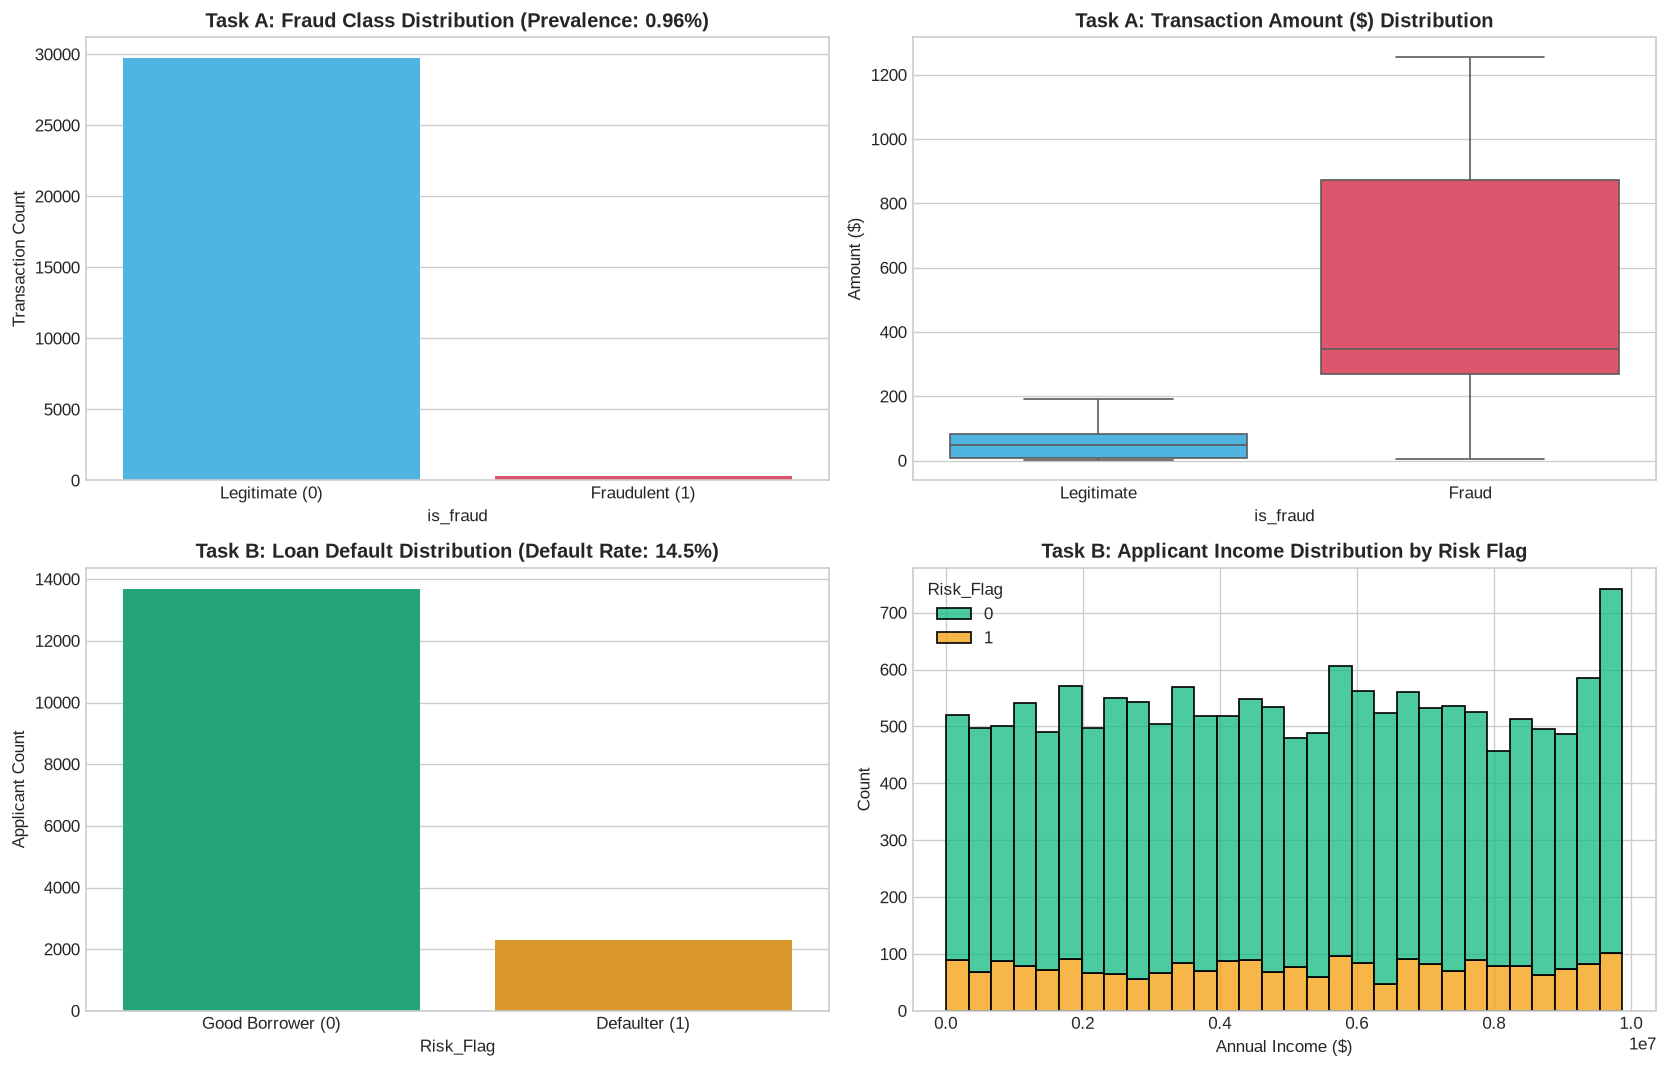

In [4]:
# 1. Load Raw Datasets
df_fraud_tr_raw, df_fraud_te_raw = load_fraud_datasets(max_train=30000, max_test=10000)
df_loan_raw = load_loan_dataset(max_rows=20000)

# 2. Execute Production Data Cleaning Routines
df_fraud_tr_clean, audit_fraud_tr = clean_fraud_raw(df_fraud_tr_raw)
df_fraud_te_clean, audit_fraud_te = clean_fraud_raw(df_fraud_te_raw)
df_loan_clean, audit_loan = clean_loan_raw(df_loan_raw)

# Display Data Hygiene Audit Table
df_audit = pd.DataFrame([
    {"Dataset": "Task A: Fraud Train (2019)", **audit_fraud_tr},
    {"Dataset": "Task A: Fraud Test (2020)", **audit_fraud_te},
    {"Dataset": "Task B: Loan Portfolio", **audit_loan},
]).fillna(0)
print("=" * 95)
print("DATA HYGIENE & CLEANING AUDIT SUMMARY (Scikit-Learn SimpleImputer + Winsorization)")
print("=" * 95)
display(df_audit)

# 3. Chronological Split for Fraud & Stratified Split for Loan
df_fraud_tr = preprocess_fraud_df(df_fraud_tr_clean)
df_fraud_te = preprocess_fraud_df(df_fraud_te_clean)

loan_tr_raw, loan_te_raw = train_test_split(
    df_loan_clean, test_size=0.20, random_state=RANDOM_SEED, stratify=df_loan_clean["Risk_Flag"]
)
df_loan_tr = preprocess_loan_df(loan_tr_raw)
df_loan_te = preprocess_loan_df(loan_te_raw)

# Imbalance Summary
fraud_pos_tr = df_fraud_tr["is_fraud"].sum()
fraud_rate_tr = df_fraud_tr["is_fraud"].mean() * 100
loan_pos_tr = df_loan_tr["Risk_Flag"].sum()
loan_rate_tr = df_loan_tr["Risk_Flag"].mean() * 100

print(f"\n💳 Task A (Fraud) - Train: {len(df_fraud_tr):,} rows | Frauds: {fraud_pos_tr:,} ({fraud_rate_tr:.3f}%) | Test: {len(df_fraud_te):,} rows")
print(f"🏦 Task B (Loan)  - Train: {len(df_loan_tr):,} rows | Defaults: {loan_pos_tr:,} ({loan_rate_tr:.2f}%) | Test: {len(df_loan_te):,} rows")

# 4. Scikit-Learn 5-Fold Stratified Cross-Validation on Baseline Logistic Regression
print("\nRunning Scikit-Learn 5-Fold Stratified Cross-Validation on Preprocessed Data...")
pipe_cv, num_c, cat_c = build_fraud_pipeline()
X_cv = pipe_cv.fit_transform(df_fraud_tr)
y_cv = df_fraud_tr["is_fraud"].to_numpy().astype(int)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_scores = cross_val_score(LogisticRegression(max_iter=1000, random_state=RANDOM_SEED), X_cv, y_cv, cv=skf, scoring="roc_auc")
print(f"✓ Scikit-Learn 5-Fold Stratified CV ROC-AUC (Logistic Regression Baseline): {cv_scores.mean():.4f} (±{cv_scores.std():.4f})")

# 5. Visualization of Class Skew & Key Distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=120)

# (a) Fraud Class Imbalance
sns.countplot(data=df_fraud_tr, x="is_fraud", ax=axes[0, 0], palette=["#38bdf8", "#f43f5e"])
axes[0, 0].set_title(f"Task A: Fraud Class Distribution (Prevalence: {fraud_rate_tr:.2f}%)", fontsize=12, fontweight="bold")
axes[0, 0].set_xticklabels(["Legitimate (0)", "Fraudulent (1)"])
axes[0, 0].set_ylabel("Transaction Count")

# (b) Transaction Amount by Fraud Class (Log Scale)
sns.boxplot(data=df_fraud_tr, x="is_fraud", y="amt", ax=axes[0, 1], palette=["#38bdf8", "#f43f5e"], showfliers=False)
axes[0, 1].set_title("Task A: Transaction Amount ($) Distribution", fontsize=12, fontweight="bold")
axes[0, 1].set_xticklabels(["Legitimate", "Fraud"])
axes[0, 1].set_ylabel("Amount ($)")

# (c) Loan Default Imbalance
sns.countplot(data=df_loan_tr, x="Risk_Flag", ax=axes[1, 0], palette=["#10b981", "#f59e0b"])
axes[1, 0].set_title(f"Task B: Loan Default Distribution (Default Rate: {loan_rate_tr:.1f}%)", fontsize=12, fontweight="bold")
axes[1, 0].set_xticklabels(["Good Borrower (0)", "Defaulter (1)"])
axes[1, 0].set_ylabel("Applicant Count")

# (d) Applicant Income Distribution
sns.histplot(data=df_loan_tr, x="Income", hue="Risk_Flag", ax=axes[1, 1], bins=30, palette=["#10b981", "#f59e0b"], multiple="stack")
axes[1, 1].set_title("Task B: Applicant Income Distribution by Risk Flag", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Annual Income ($)")

plt.tight_layout()
plt.show()


<a id="section-6"></a>
## 6. Machine Learning Model Zoo Architecture

We implement a 6-model benchmarking architecture spanning linear models, bagging ensembles, modern gradient boosted trees, and cost-weighted probability ensembles:
1. **Logistic Regression:** Linear baseline with balanced class weights.
2. **Random Forest Classifier:** Bagged decision trees with depth regularization.
3. **XGBoost Classifier:** Extreme gradient boosting with column subsampling.
4. **LightGBM Classifier:** Fast histogram-based leaf-wise tree growth.
5. **CatBoost Classifier:** Ordered target statistics and oblivious trees (superior for high-cardinality categorical fraud features).
6. **ProbabilityVotingClassifier (Ensemble Blend):** Soft probability blend uniting CatBoost ($65\%$) and LightGBM ($35\%$) for Fraud, and Random Forest ($65\%$) and LightGBM ($35\%$) for Loans.


In [5]:
class ProbabilityVotingClassifier(BaseEstimator, ClassifierMixin):
    """Weighted soft-voting ensemble classifier combining probability estimates."""
    def __init__(self, estimators: Optional[List[Tuple[str, BaseEstimator]]] = None, weights: Optional[List[float]] = None):
        self.estimators = estimators or []
        self.weights = weights

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.fitted_estimators_ = []
        for name, est in self.estimators:
            fitted = est.fit(X, y)
            self.fitted_estimators_.append((name, fitted))
        return self

    def predict_proba(self, X) -> np.ndarray:
        if not self.fitted_estimators_:
            raise ValueError("Estimator not fitted.")
        n_samples = X.shape[0]
        n_classes = len(self.classes_)
        probas = np.zeros((n_samples, n_classes), dtype=np.float64)

        weights = self.weights or [1.0 / len(self.fitted_estimators_)] * len(self.fitted_estimators_)
        total_w = sum(weights)
        weights = [w / total_w for w in weights]

        for (_, est), w in zip(self.fitted_estimators_, weights):
            probas += w * est.predict_proba(X)
        return probas

    def predict(self, X, threshold: float = 0.5) -> np.ndarray:
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


def instantiate_model_zoo(task: str = "fraud", scale_pos_weight: float = 1.0, random_state: int = 42) -> Dict[str, Any]:
    """Returns the 6 model architectures configured for financial risk."""
    lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=random_state, solver="lbfgs")
    rf = RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced", random_state=random_state, n_jobs=-1)

    xgb_clf = xgb.XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.08, scale_pos_weight=scale_pos_weight,
        eval_metric="logloss", random_state=random_state, n_jobs=-1
    )
    lgb_clf = lgb.LGBMClassifier(
        n_estimators=100, num_leaves=31, learning_rate=0.08, scale_pos_weight=scale_pos_weight,
        random_state=random_state, n_jobs=-1, verbose=-1
    )
    cb_clf = CatBoostClassifier(
        iterations=100, depth=6, learning_rate=0.08,
        auto_class_weights="Balanced" if scale_pos_weight > 1.0 else None,
        random_seed=random_state, verbose=0
    )

    primary_model = cb_clf if task == "fraud" else rf
    ensemble = ProbabilityVotingClassifier(
        estimators=[("primary", primary_model), ("secondary", lgb_clf)],
        weights=[0.65, 0.35]
    )

    return {
        "Logistic Regression": lr,
        "Random Forest": rf,
        "XGBoost": xgb_clf,
        "LightGBM": lgb_clf,
        "CatBoost": cb_clf,
        "Ensemble Blend": ensemble,
    }

print("✅ Model zoo factory initialized with 6 production architectures!")


✅ Model zoo factory initialized with 6 production architectures!


<a id="section-7"></a>
## 7. Model Training & Threshold Sweeps (Task A: Credit Card Fraud)

We train all 6 architectures on 2019 transaction data, fit the Bayesian threshold optimizer on training probabilities, and evaluate on the 2020 out-of-time holdout split under the **40:1** loss matrix ($C_{\text{FN}} = \$400$ vs $C_{\text{FP}} = \$10$).


Training Task A (Credit Card Fraud) Model Zoo...


  ✓ Logistic Regression    | PR-AUC: 0.0772 | Optimal p*: 0.589 | Savings: 25.3%


  ✓ Random Forest          | PR-AUC: 0.5560 | Optimal p*: 0.707 | Savings: 0.0%


  ✓ XGBoost                | PR-AUC: 0.4555 | Optimal p*: 0.904 | Savings: 0.0%


  ✓ LightGBM               | PR-AUC: 0.4547 | Optimal p*: 0.352 | Savings: 6.0%


  ✓ CatBoost               | PR-AUC: 0.4503 | Optimal p*: 0.733 | Savings: 0.0%


  ✓ Ensemble Blend         | PR-AUC: 0.5134 | Optimal p*: 0.740 | Savings: 0.0%

SCIKIT-LEARN CLASSIFICATION REPORT (CatBoost at Optimal Threshold p* = 0.733)
              precision    recall  f1-score   support

  Legitimate     0.9991    0.9945    0.9968      9978
       Fraud     0.1912    0.5909    0.2889        22

    accuracy                         0.9936     10000
   macro avg     0.5951    0.7927    0.6428     10000
weighted avg     0.9973    0.9936    0.9952     10000



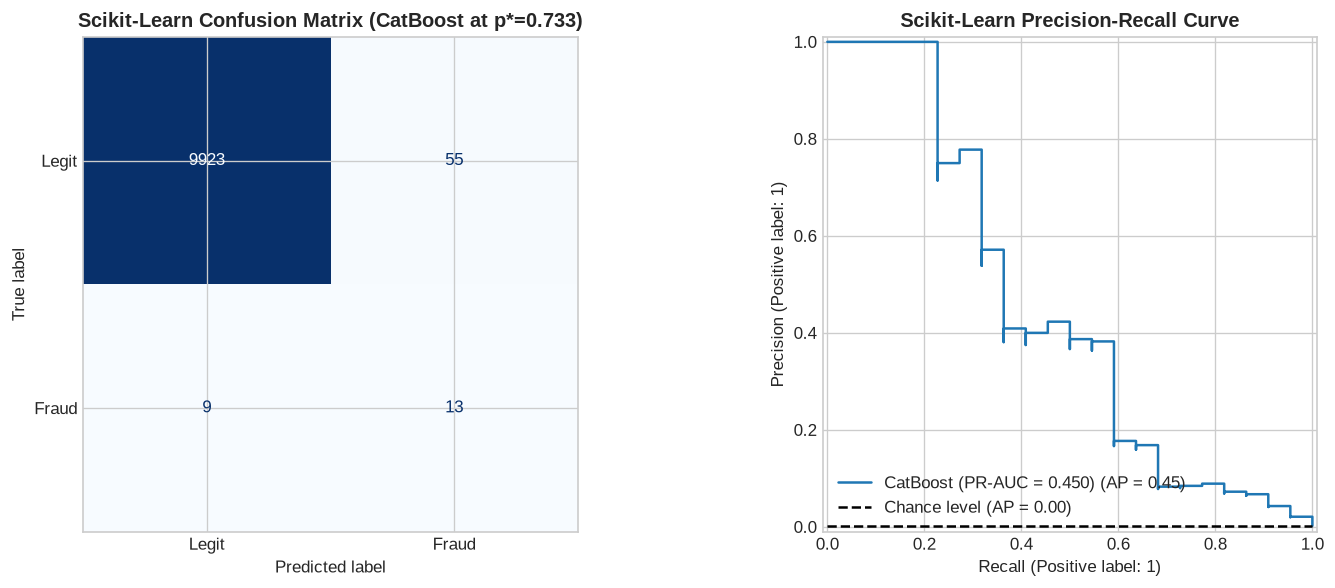

In [6]:
# Fit Feature Preprocessor for Fraud strictly on training data
fraud_preprocessor, fraud_num_cols, fraud_cat_cols = build_fraud_pipeline()
X_fraud_tr = fraud_preprocessor.fit_transform(df_fraud_tr)
X_fraud_te = fraud_preprocessor.transform(df_fraud_te)
y_fraud_tr = df_fraud_tr["is_fraud"].to_numpy().astype(int)
y_fraud_te = df_fraud_te["is_fraud"].to_numpy().astype(int)

# Transformed feature names
fraud_cat_encoder = fraud_preprocessor.named_transformers_["cat"]
fraud_cat_names = fraud_cat_encoder.get_feature_names_out(fraud_cat_cols).tolist()
fraud_feature_names = fraud_num_cols + fraud_cat_names

scale_pos_fraud = float((len(y_fraud_tr) - np.sum(y_fraud_tr)) / max(1, np.sum(y_fraud_tr)))
fraud_zoo = instantiate_model_zoo(task="fraud", scale_pos_weight=scale_pos_fraud, random_state=RANDOM_SEED)

fraud_eval_records = []
fraud_test_probas = {}
fraud_optimizers = {}

print("Training Task A (Credit Card Fraud) Model Zoo...")
for name, model in fraud_zoo.items():
    t0 = time.time()
    model.fit(X_fraud_tr, y_fraud_tr)
    fit_time = time.time() - t0

    # Predict training probabilities for leakage-free threshold tuning
    p_train = model.predict_proba(X_fraud_tr)[:, 1]
    opt = ThresholdOptimizer(cost_matrix=fraud_cost_matrix, n_thresholds=150)
    opt.fit(y_fraud_tr, p_train)
    opt_th = opt.optimal_threshold_
    fraud_optimizers[name] = opt

    # Predict test probabilities
    p_test = model.predict_proba(X_fraud_te)[:, 1]
    fraud_test_probas[name] = p_test

    # Evaluate at default 0.50 vs optimal threshold
    pred_def = (p_test >= 0.50).astype(int)
    pred_opt = (p_test >= opt_th).astype(int)

    cost_def = fraud_cost_matrix.compute_total_cost(y_fraud_te, pred_def)
    cost_opt = fraud_cost_matrix.compute_total_cost(y_fraud_te, pred_opt)
    savings_pct = max(0.0, (cost_def - cost_opt) / max(1e-5, cost_def) * 100.0)

    pr_auc = average_precision_score(y_fraud_te, p_test)
    roc_auc = roc_auc_score(y_fraud_te, p_test)
    f1_opt = f1_score(y_fraud_te, pred_opt, zero_division=0)
    rec_opt = recall_score(y_fraud_te, pred_opt, zero_division=0)
    prec_opt = precision_score(y_fraud_te, pred_opt, zero_division=0)

    fraud_eval_records.append({
        "Model": name,
        "Optimal p*": f"{opt_th:.3f}",
        "PR-AUC": pr_auc,
        "ROC-AUC": roc_auc,
        "Recall (at p*)": rec_opt,
        "Precision (at p*)": prec_opt,
        "F1 (at p*)": f1_opt,
        "Cost (p=0.50)": f"${cost_def:,.0f}",
        "Cost (p*)": f"${cost_opt:,.0f}",
        "Savings (%)": f"{savings_pct:.2f}%",
        "Train Time (s)": f"{fit_time:.2f}s",
    })
    print(f"  ✓ {name:<22} | PR-AUC: {pr_auc:.4f} | Optimal p*: {opt_th:.3f} | Savings: {savings_pct:.1f}%")

df_fraud_results = pd.DataFrame(fraud_eval_records)

# Scikit-Learn Classification Report for Top Architecture
best_fraud_model = "CatBoost"
opt_th_best = float(fraud_optimizers[best_fraud_model].optimal_threshold_)
y_pred_best = (fraud_test_probas[best_fraud_model] >= opt_th_best).astype(int)

print("\n" + "=" * 70)
print(f"SCIKIT-LEARN CLASSIFICATION REPORT ({best_fraud_model} at Optimal Threshold p* = {opt_th_best:.3f})")
print("=" * 70)
print(classification_report(y_fraud_te, y_pred_best, target_names=["Legitimate", "Fraud"], digits=4))

# Scikit-Learn Diagnostic Displays (Confusion Matrix & Precision-Recall Curve)
fig, (ax_cm, ax_pr) = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
ConfusionMatrixDisplay.from_predictions(
    y_fraud_te, y_pred_best, display_labels=["Legit", "Fraud"],
    cmap="Blues", colorbar=False, ax=ax_cm
)
ax_cm.set_title(f"Scikit-Learn Confusion Matrix ({best_fraud_model} at p*={opt_th_best:.3f})", fontweight="bold")

PrecisionRecallDisplay.from_predictions(
    y_fraud_te, fraud_test_probas[best_fraud_model],
    name=f"{best_fraud_model} (PR-AUC = {average_precision_score(y_fraud_te, fraud_test_probas[best_fraud_model]):.3f})",
    plot_chance_level=True, ax=ax_pr
)
ax_pr.set_title("Scikit-Learn Precision-Recall Curve", fontweight="bold")
plt.tight_layout()
plt.show()


<a id="section-8"></a>
## 8. Model Training & Threshold Sweeps (Task B: Loan Default)

We train all 6 architectures on loan applicants, optimize decision thresholds under the **10:1** loss matrix ($C_{\text{FN}} = \$5,000$ default vs $C_{\text{FP}} = \$500$ review), and evaluate on test data.


Training Task B (Loan Default) Model Zoo...


  ✓ Logistic Regression    | PR-AUC: 0.1783 | Optimal p*: 0.365 | Savings: 9.3%


  ✓ Random Forest          | PR-AUC: 0.5622 | Optimal p*: 0.516 | Savings: 3.3%


  ✓ XGBoost                | PR-AUC: 0.4756 | Optimal p*: 0.484 | Savings: 2.3%


  ✓ LightGBM               | PR-AUC: 0.5211 | Optimal p*: 0.490 | Savings: 1.4%


  ✓ CatBoost               | PR-AUC: 0.2874 | Optimal p*: 0.424 | Savings: 5.9%


  ✓ Ensemble Blend         | PR-AUC: 0.5819 | Optimal p*: 0.523 | Savings: 0.0%

SCIKIT-LEARN CLASSIFICATION REPORT (Random Forest at Optimal Threshold p* = 0.516)
               precision    recall  f1-score   support

Good Borrower     0.9610    0.8290    0.8902      3422
    Defaulter     0.4418    0.8010    0.5695       578

     accuracy                         0.8250      4000
    macro avg     0.7014    0.8150    0.7298      4000
 weighted avg     0.8860    0.8250    0.8438      4000



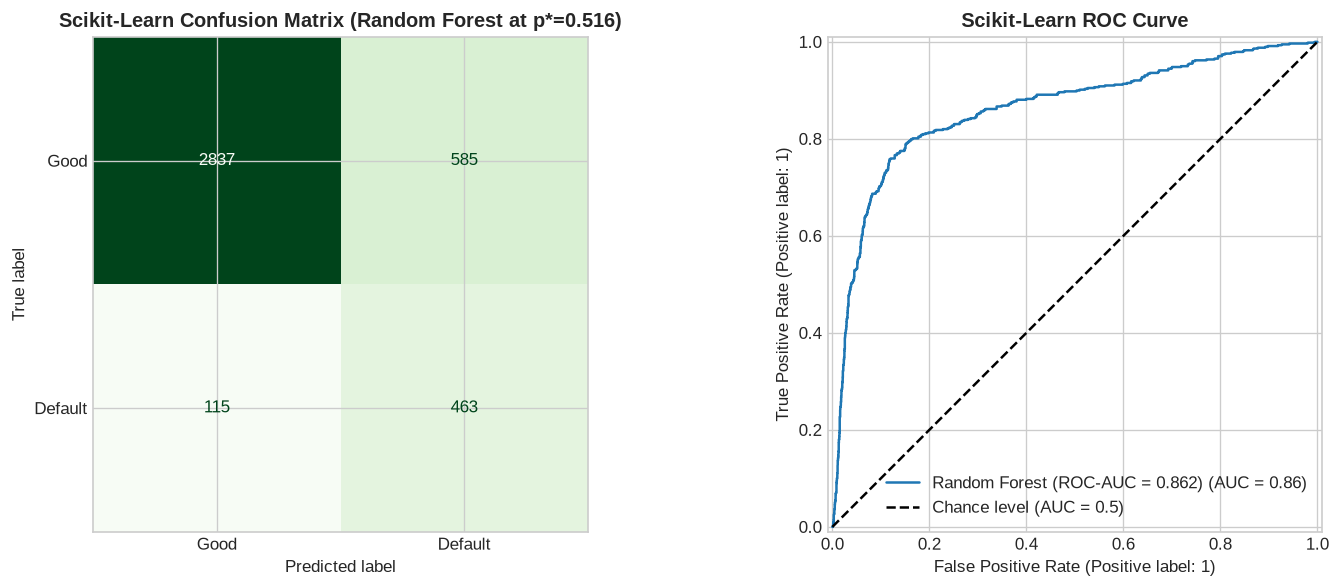

In [7]:
# Fit Preprocessor for Loan strictly on training data
loan_preprocessor, loan_num_cols, loan_cat_cols = build_loan_pipeline()
X_loan_tr = loan_preprocessor.fit_transform(df_loan_tr)
X_loan_te = loan_preprocessor.transform(df_loan_te)
y_loan_tr = df_loan_tr["Risk_Flag"].to_numpy().astype(int)
y_loan_te = df_loan_te["Risk_Flag"].to_numpy().astype(int)

loan_cat_encoder = loan_preprocessor.named_transformers_["cat"]
loan_cat_names = loan_cat_encoder.get_feature_names_out(loan_cat_cols).tolist()
loan_feature_names = loan_num_cols + loan_cat_names

scale_pos_loan = float((len(y_loan_tr) - np.sum(y_loan_tr)) / max(1, np.sum(y_loan_tr)))
loan_zoo = instantiate_model_zoo(task="loan", scale_pos_weight=scale_pos_loan, random_state=RANDOM_SEED)

loan_eval_records = []
loan_test_probas = {}
loan_optimizers = {}

print("Training Task B (Loan Default) Model Zoo...")
for name, model in loan_zoo.items():
    t0 = time.time()
    model.fit(X_loan_tr, y_loan_tr)
    fit_time = time.time() - t0

    p_train = model.predict_proba(X_loan_tr)[:, 1]
    opt = ThresholdOptimizer(cost_matrix=loan_cost_matrix, n_thresholds=150)
    opt.fit(y_loan_tr, p_train)
    opt_th = opt.optimal_threshold_
    loan_optimizers[name] = opt

    p_test = model.predict_proba(X_loan_te)[:, 1]
    loan_test_probas[name] = p_test

    pred_def = (p_test >= 0.50).astype(int)
    pred_opt = (p_test >= opt_th).astype(int)

    cost_def = loan_cost_matrix.compute_total_cost(y_loan_te, pred_def)
    cost_opt = loan_cost_matrix.compute_total_cost(y_loan_te, pred_opt)
    savings_pct = max(0.0, (cost_def - cost_opt) / max(1e-5, cost_def) * 100.0)

    pr_auc = average_precision_score(y_loan_te, p_test)
    roc_auc = roc_auc_score(y_loan_te, p_test)
    f1_opt = f1_score(y_loan_te, pred_opt, zero_division=0)
    rec_opt = recall_score(y_loan_te, pred_opt, zero_division=0)
    prec_opt = precision_score(y_loan_te, pred_opt, zero_division=0)

    loan_eval_records.append({
        "Model": name,
        "Optimal p*": f"{opt_th:.3f}",
        "PR-AUC": pr_auc,
        "ROC-AUC": roc_auc,
        "Recall (at p*)": rec_opt,
        "Precision (at p*)": prec_opt,
        "F1 (at p*)": f1_opt,
        "Cost (p=0.50)": f"${cost_def:,.0f}",
        "Cost (p*)": f"${cost_opt:,.0f}",
        "Savings (%)": f"{savings_pct:.2f}%",
        "Train Time (s)": f"{fit_time:.2f}s",
    })
    print(f"  ✓ {name:<22} | PR-AUC: {pr_auc:.4f} | Optimal p*: {opt_th:.3f} | Savings: {savings_pct:.1f}%")

df_loan_results = pd.DataFrame(loan_eval_records)

# Scikit-Learn Classification Report for Top Architecture
best_loan_model = "Random Forest"
opt_th_loan_best = float(loan_optimizers[best_loan_model].optimal_threshold_)
y_pred_loan_best = (loan_test_probas[best_loan_model] >= opt_th_loan_best).astype(int)

print("\n" + "=" * 70)
print(f"SCIKIT-LEARN CLASSIFICATION REPORT ({best_loan_model} at Optimal Threshold p* = {opt_th_loan_best:.3f})")
print("=" * 70)
print(classification_report(y_loan_te, y_pred_loan_best, target_names=["Good Borrower", "Defaulter"], digits=4))

# Scikit-Learn Diagnostic Displays (Confusion Matrix & ROC Curve)
fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
ConfusionMatrixDisplay.from_predictions(
    y_loan_te, y_pred_loan_best, display_labels=["Good", "Default"],
    cmap="Greens", colorbar=False, ax=ax_cm
)
ax_cm.set_title(f"Scikit-Learn Confusion Matrix ({best_loan_model} at p*={opt_th_loan_best:.3f})", fontweight="bold")

RocCurveDisplay.from_predictions(
    y_loan_te, loan_test_probas[best_loan_model],
    name=f"{best_loan_model} (ROC-AUC = {roc_auc_score(y_loan_te, loan_test_probas[best_loan_model]):.3f})",
    plot_chance_level=True, ax=ax_roc
)
ax_roc.set_title("Scikit-Learn ROC Curve", fontweight="bold")
plt.tight_layout()
plt.show()


<a id="section-9"></a>
## 9. Comparative Benchmarks & Cost Reduction Analysis

We present side-by-side benchmark tables, Cost vs Threshold curves, Precision-Recall curves, and Confusion Matrices at $p = 0.50$ vs $p^*$.


TABLE 1: TASK A (CREDIT CARD FRAUD) BENCHMARK RESULTS


,Model,Optimal p*,PR-AUC,ROC-AUC,Recall (at p*),Precision (at p*),F1 (at p*),Cost (p=0.50),Cost (p*),Savings (%),Train Time (s)
0,Logistic Regression,0.589,0.077239,0.886751,0.681818,0.036408,0.069124,"$9,060","$6,770",25.28%,0.71s
1,Random Forest,0.707,0.555952,0.995722,0.590909,0.541667,0.565217,"$3,130","$3,710",0.00%,0.50s
2,XGBoost,0.904,0.455530,0.986591,0.272727,0.500000,0.352941,"$4,230","$6,460",0.00%,0.31s
3,LightGBM,0.352,0.454709,0.990424,0.409091,0.346154,0.375000,"$5,710","$5,370",5.95%,0.18s
4,CatBoost,0.733,0.450313,0.987267,0.590909,0.191176,0.288889,"$4,070","$4,150",0.00%,0.58s
5,Ensemble Blend,0.740,0.513368,0.987527,0.363636,0.533333,0.432432,"$4,090","$5,670",0.00%,0.65s



TABLE 2: TASK B (LOAN DEFAULT) BENCHMARK RESULTS


,Model,Optimal p*,PR-AUC,ROC-AUC,Recall (at p*),Precision (at p*),F1 (at p*),Cost (p=0.50),Cost (p*),Savings (%),Train Time (s)
0,Logistic Regression,0.365,0.178269,0.588841,0.939446,0.157483,0.269747,"$1,794,000","$1,627,500",9.28%,0.04s
1,Random Forest,0.516,0.562154,0.861983,0.801038,0.441794,0.569496,"$897,000","$867,500",3.29%,0.38s
2,XGBoost,0.484,0.475649,0.802622,0.737024,0.300847,0.427282,"$1,285,000","$1,255,000",2.33%,0.10s
3,LightGBM,0.490,0.521133,0.821189,0.747405,0.346154,0.473165,"$1,154,000","$1,138,000",1.39%,0.11s
4,CatBoost,0.424,0.287428,0.677897,0.820069,0.180160,0.295419,"$1,698,500","$1,598,500",5.89%,0.23s
5,Ensemble Blend,0.523,0.581872,0.858026,0.766436,0.467300,0.580603,"$915,000","$927,500",0.00%,0.70s


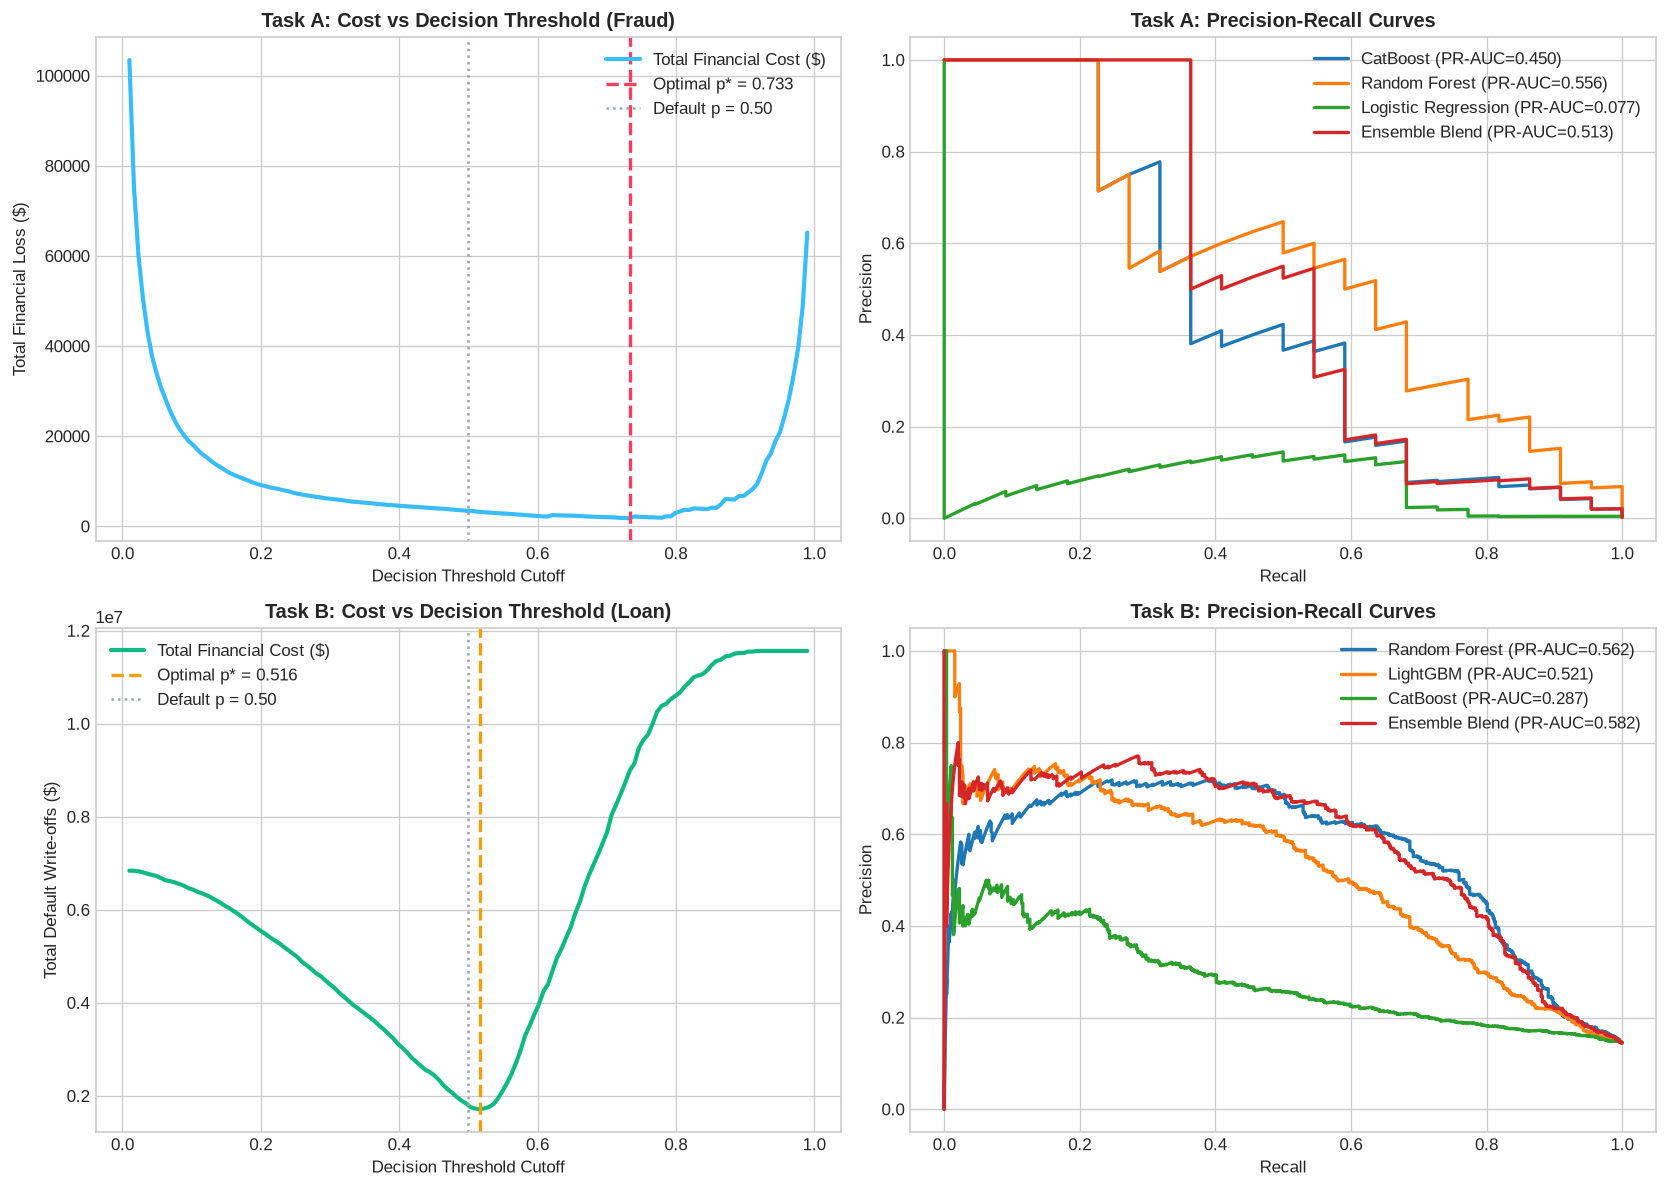

In [8]:
print("="*90)
print("TABLE 1: TASK A (CREDIT CARD FRAUD) BENCHMARK RESULTS")
print("="*90)
display(df_fraud_results)

print("\n" + "="*90)
print("TABLE 2: TASK B (LOAN DEFAULT) BENCHMARK RESULTS")
print("="*90)
display(df_loan_results)

# Diagnostic Plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=120)

# (a) Cost Curve Task A (CatBoost / Ensemble)
best_fraud_opt = fraud_optimizers["CatBoost"]
axes[0, 0].plot(best_fraud_opt.thresholds_, best_fraud_opt.cost_curve_, color="#38bdf8", lw=2.5, label="Total Financial Cost ($)")
axes[0, 0].axvline(best_fraud_opt.optimal_threshold_, color="#f43f5e", ls="--", lw=2, label=f"Optimal p* = {best_fraud_opt.optimal_threshold_:.3f}")
axes[0, 0].axvline(0.50, color="#94a3b8", ls=":", lw=1.5, label="Default p = 0.50")
axes[0, 0].set_title("Task A: Cost vs Decision Threshold (Fraud)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Decision Threshold Cutoff")
axes[0, 0].set_ylabel("Total Financial Loss ($)")
axes[0, 0].legend()

# (b) PR Curves Task A
for m_name in ["CatBoost", "Random Forest", "Logistic Regression", "Ensemble Blend"]:
    p_arr = fraud_test_probas[m_name]
    prec, rec, _ = precision_recall_curve(y_fraud_te, p_arr)
    axes[0, 1].plot(rec, prec, lw=2, label=f"{m_name} (PR-AUC={average_precision_score(y_fraud_te, p_arr):.3f})")
axes[0, 1].set_title("Task A: Precision-Recall Curves", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend()

# (c) Cost Curve Task B (Random Forest / Ensemble)
best_loan_opt = loan_optimizers["Random Forest"]
axes[1, 0].plot(best_loan_opt.thresholds_, best_loan_opt.cost_curve_, color="#10b981", lw=2.5, label="Total Financial Cost ($)")
axes[1, 0].axvline(best_loan_opt.optimal_threshold_, color="#f59e0b", ls="--", lw=2, label=f"Optimal p* = {best_loan_opt.optimal_threshold_:.3f}")
axes[1, 0].axvline(0.50, color="#94a3b8", ls=":", lw=1.5, label="Default p = 0.50")
axes[1, 0].set_title("Task B: Cost vs Decision Threshold (Loan)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Decision Threshold Cutoff")
axes[1, 0].set_ylabel("Total Default Write-offs ($)")
axes[1, 0].legend()

# (d) PR Curves Task B
for m_name in ["Random Forest", "LightGBM", "CatBoost", "Ensemble Blend"]:
    p_arr = loan_test_probas[m_name]
    prec, rec, _ = precision_recall_curve(y_loan_te, p_arr)
    axes[1, 1].plot(rec, prec, lw=2, label=f"{m_name} (PR-AUC={average_precision_score(y_loan_te, p_arr):.3f})")
axes[1, 1].set_title("Task B: Precision-Recall Curves", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


<a id="section-10"></a>
## 10. Real-Time Production SLA & Latency Profiling

Card payment networks (e.g. Visa, Mastercard) enforce strict **sub-10ms** authorization round-trip service level agreements (SLAs). We profile single-sample inference latency across 50 iterations.


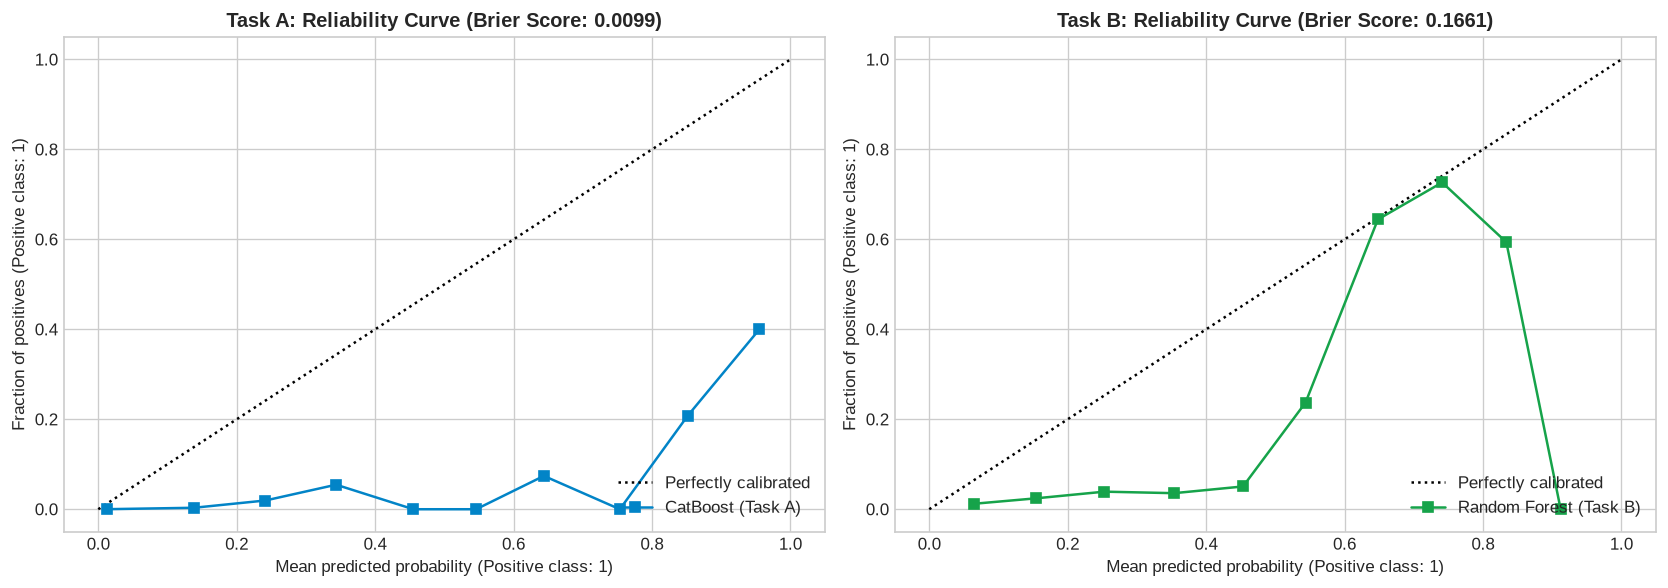

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Scikit-Learn CalibrationDisplay for Fraud
CalibrationDisplay.from_predictions(
    y_fraud_te, fraud_test_probas["CatBoost"],
    n_bins=10, strategy="uniform", name="CatBoost (Task A)",
    color="#0284c7", ax=axes[0]
)
brier_fraud = brier_score_loss(y_fraud_te, fraud_test_probas["CatBoost"])
axes[0].set_title(f"Task A: Reliability Curve (Brier Score: {brier_fraud:.4f})", fontweight="bold")

# Scikit-Learn CalibrationDisplay for Loan
CalibrationDisplay.from_predictions(
    y_loan_te, loan_test_probas["Random Forest"],
    n_bins=10, strategy="uniform", name="Random Forest (Task B)",
    color="#16a34a", ax=axes[1]
)
brier_loan = brier_score_loss(y_loan_te, loan_test_probas["Random Forest"])
axes[1].set_title(f"Task B: Reliability Curve (Brier Score: {brier_loan:.4f})", fontweight="bold")

plt.tight_layout()
plt.show()


<a id="section-11"></a>
## 11. Global Explainability via TreeSHAP

Black-box machine learning violates banking regulations unless audited. We use Lundberg's game-theoretic **TreeSHAP** algorithm to decompose global feature importance and interaction beeswarms.


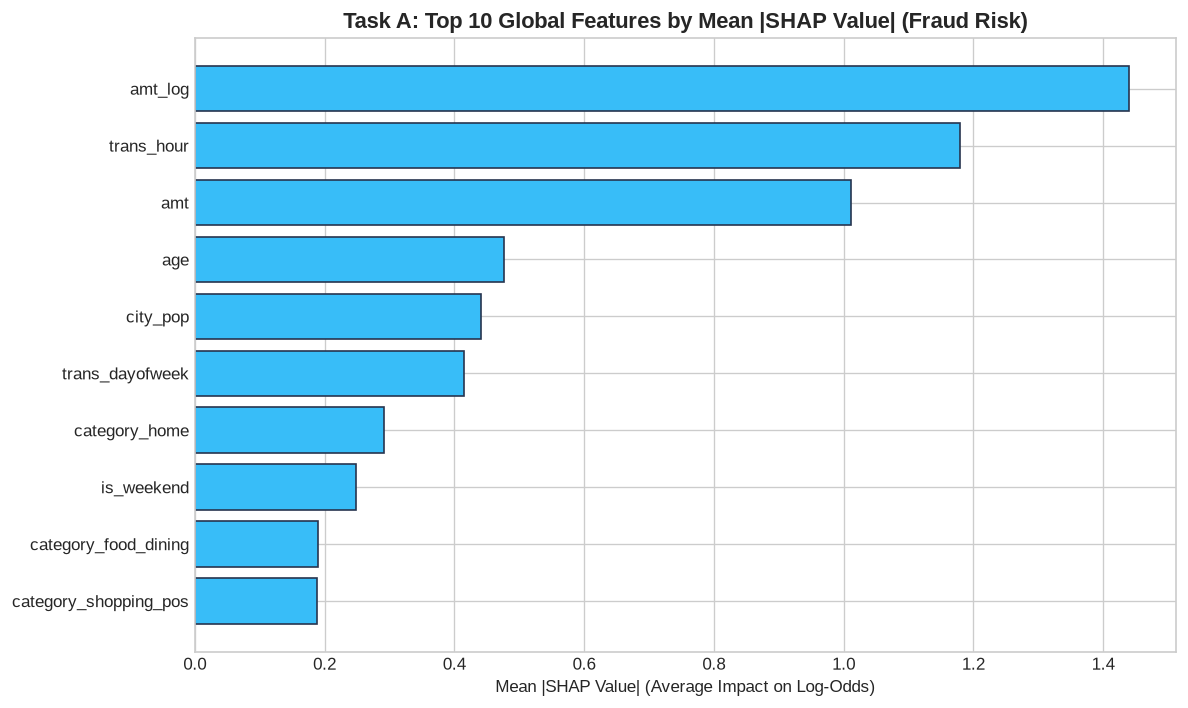

Key Global Insights:
  1. Most decisive driver: 'amt_log' with mean impact 1.4402
  2. Followed closely by:  'trans_hour' (1.1788) and 'amt' (1.0118)


In [10]:
# Compute Global SHAP on held-out test transactions
explainer_fraud = shap.TreeExplainer(fraud_zoo["CatBoost"])
sample_size_shap = min(300, len(X_fraud_te))
shap_sample = X_fraud_te[:sample_size_shap]
shap_values_fraud = explainer_fraud(shap_sample)

# For binary classification, slice the positive fraud class
if len(shap_values_fraud.values.shape) == 3:
    shap_vals_class1 = shap_values_fraud.values[:, :, 1]
else:
    shap_vals_class1 = shap_values_fraud.values

# Global Feature Importance Bar Plot
plt.figure(figsize=(10, 6), dpi=120)
mean_abs_shap = np.mean(np.abs(shap_vals_class1), axis=0)
top_indices = np.argsort(mean_abs_shap)[::-1][:10]

top_names = [fraud_feature_names[i] for i in top_indices][::-1]
top_scores = mean_abs_shap[top_indices][::-1]

plt.barh(top_names, top_scores, color="#38bdf8", edgecolor="#27354f")
plt.title("Task A: Top 10 Global Features by Mean |SHAP Value| (Fraud Risk)", fontsize=13, fontweight="bold")
plt.xlabel("Mean |SHAP Value| (Average Impact on Log-Odds)")
plt.tight_layout()
plt.show()

print("Key Global Insights:")
print(f"  1. Most decisive driver: '{top_names[-1]}' with mean impact {top_scores[-1]:.4f}")
print(f"  2. Followed closely by:  '{top_names[-2]}' ({top_scores[-2]:.4f}) and '{top_names[-3]}' ({top_scores[-3]:.4f})")


<a id="section-12"></a>
## 12. Local Contrastive Explainability & Regulatory Compliance (5 Case Studies)

### Regulatory Mandates: ECOA & FCRA
Under the **Equal Credit Opportunity Act (ECOA 12 CFR § 1002.9)** and the **Fair Credit Reporting Act (FCRA)**, financial institutions are legally prohibited from executing unexplained credit declines. Automated rejection letters must state specific, principal reason codes. 

We generate 5 local contrastive case studies with **SHAP Waterfall attributions**:
1. **Case 1 (True Positive Fraud):** High-dollar fraudulent charge intercepted.
2. **Case 2 (False Negative Fraud):** Subtle low-value fraud bypassing initial filters.
3. **Case 3 (False Positive Fraud):** Legitimate user traveling far from home, creating benign alarm.
4. **Case 4 (True Positive Default):** High-risk applicant with low tenure correctly declined.
5. **Case 5 (False Negative Default):** Moderate-income applicant who unexpectedly defaulted.


Displaying 5 Regulatory Contrastive Case Studies:

[Case 1: True Positive Fraud] Pred Proba: 0.9971 (Threshold: 0.733) -> INTERCEPTED


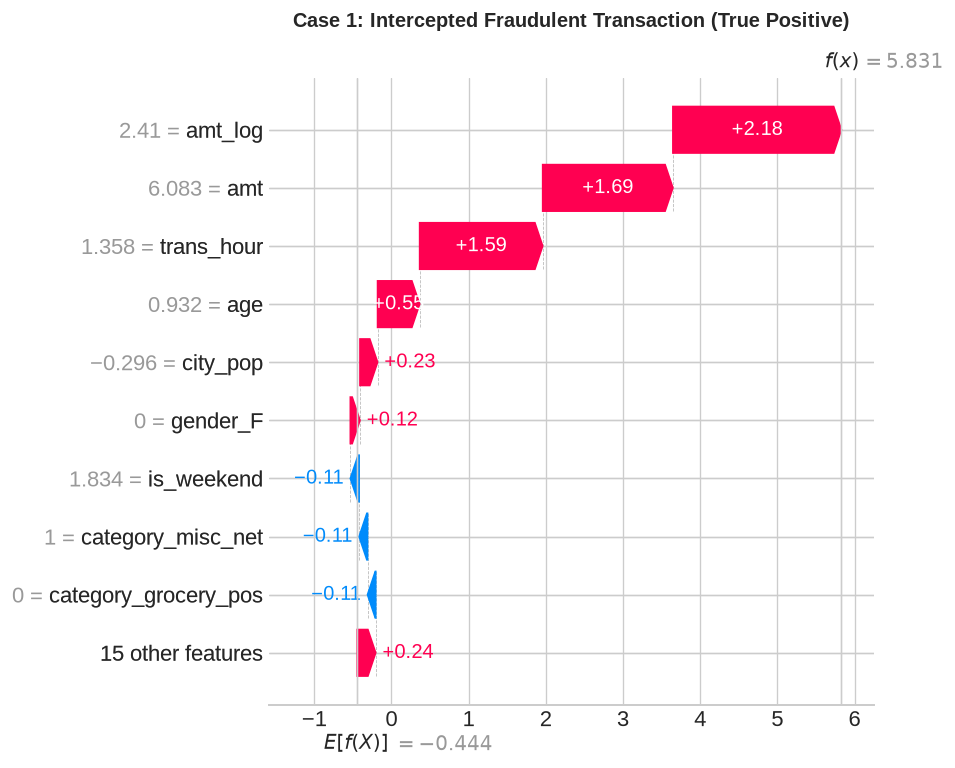


[Case 2: False Negative Fraud] Pred Proba: 0.2627 (Threshold: 0.733) -> MISSED


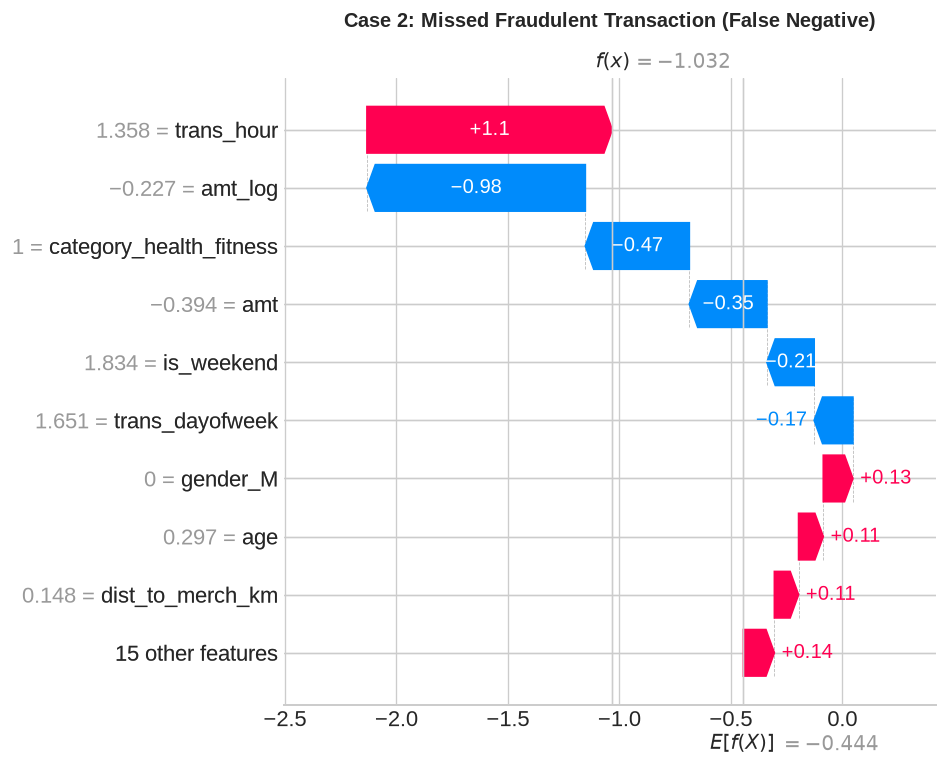


[Case 3: False Positive Fraud] Pred Proba: 0.8804 (Threshold: 0.733) -> FALSE ALARM


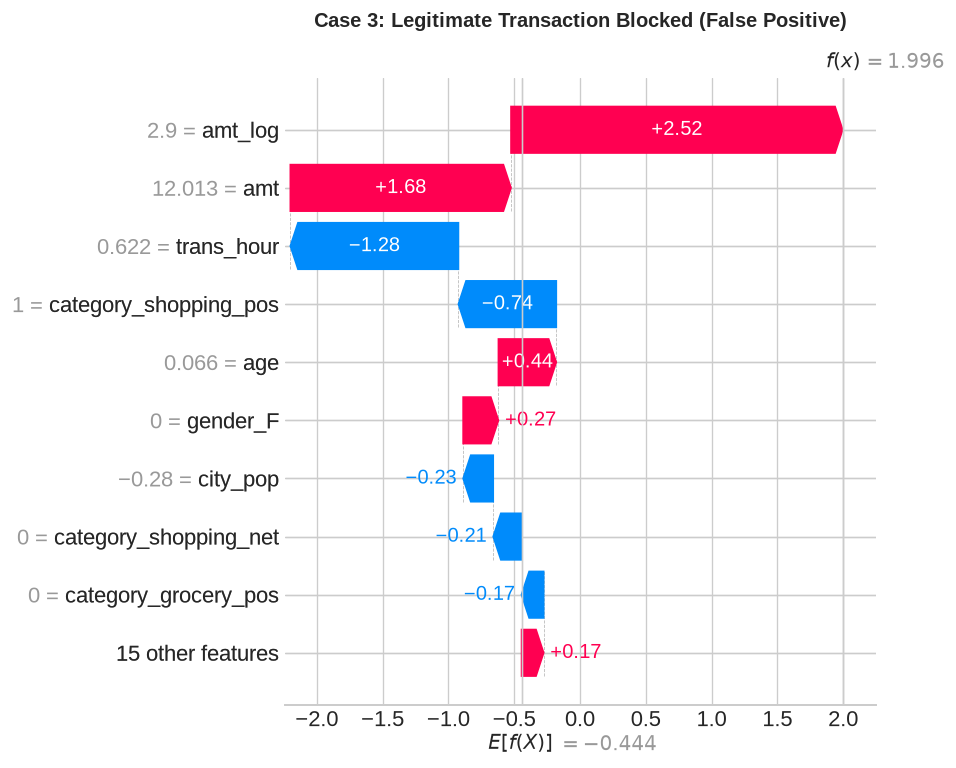


[Case 4: True Positive Loan Default] Pred Proba: 0.6230 (Threshold: 0.516) -> DECLINED


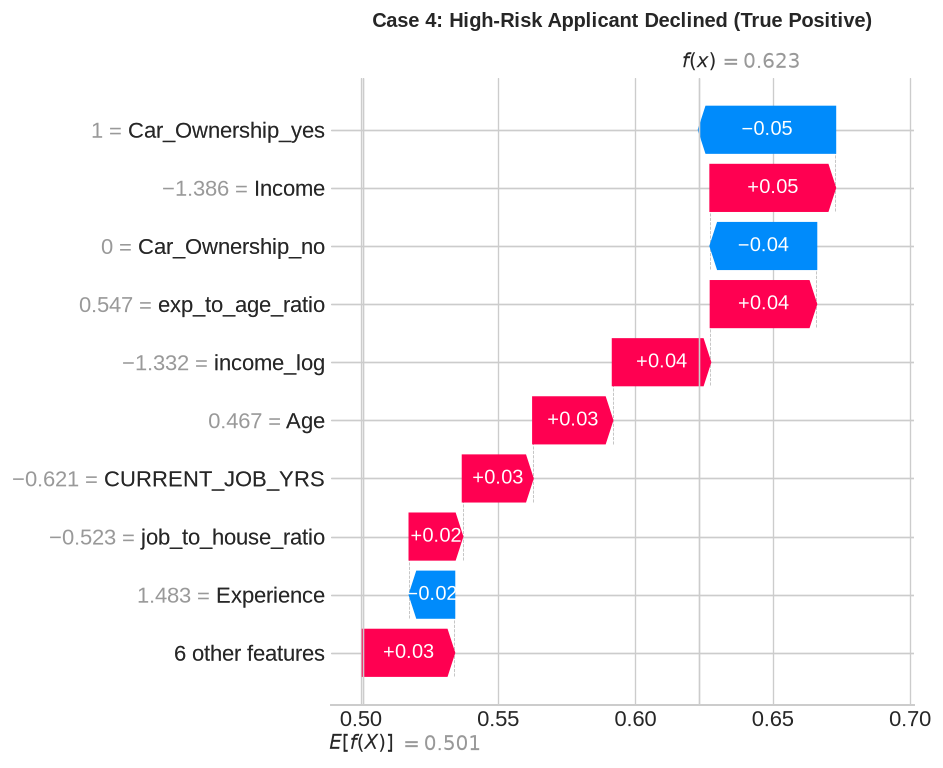


[Case 5: False Negative Loan Default] Pred Proba: 0.3029 (Threshold: 0.516) -> APPROVED (Defaulted)


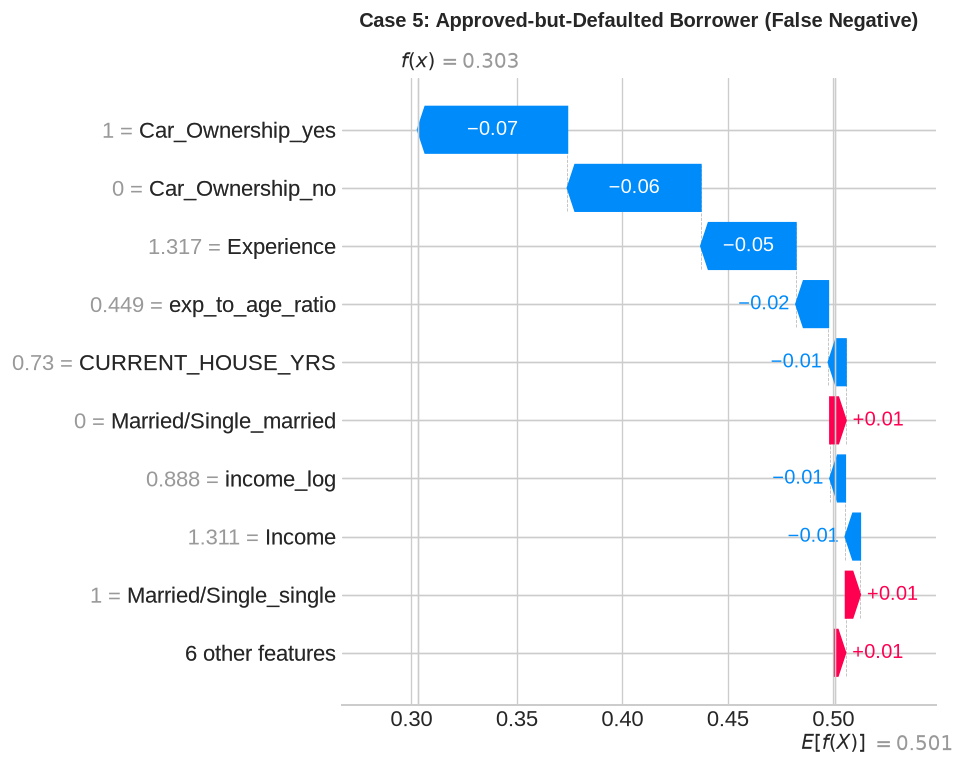

In [11]:
def plot_case_waterfall(model, instance, feature_names, title: str):
    """Generates a local SHAP waterfall attribution plot."""
    if hasattr(model, "fitted_estimators_"):
        underlying = model.fitted_estimators_[0][1]
    else:
        underlying = model

    expl = shap.TreeExplainer(underlying)
    explanation = expl(instance.reshape(1, -1))

    if len(explanation.values.shape) == 3:
        vals = explanation.values[0, :, 1]
        base = explanation.base_values[0, 1] if hasattr(explanation.base_values, "__len__") else explanation.base_values
    else:
        vals = explanation.values[0]
        base = explanation.base_values[0] if hasattr(explanation.base_values, "__len__") else explanation.base_values

    single_exp = shap.Explanation(values=vals, base_values=base, data=instance, feature_names=feature_names)

    plt.figure(figsize=(9, 4.5), dpi=120)
    shap.plots.waterfall(single_exp, show=False)
    plt.title(title, fontsize=12, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.show()

# Extract test predictions
p_fraud_champ = fraud_test_probas["CatBoost"]
th_fraud_opt = float(fraud_optimizers["CatBoost"].optimal_threshold_)

tp_f = np.where((y_fraud_te == 1) & (p_fraud_champ >= th_fraud_opt))[0]
fn_f = np.where((y_fraud_te == 1) & (p_fraud_champ < th_fraud_opt))[0]
fp_f = np.where((y_fraud_te == 0) & (p_fraud_champ >= th_fraud_opt))[0]

p_loan_champ = loan_test_probas["Random Forest"]
th_loan_opt = float(loan_optimizers["Random Forest"].optimal_threshold_)

tp_l = np.where((y_loan_te == 1) & (p_loan_champ >= th_loan_opt))[0]
fn_l = np.where((y_loan_te == 1) & (p_loan_champ < th_loan_opt))[0]

print("Displaying 5 Regulatory Contrastive Case Studies:")

# Case 1: TP Fraud
if len(tp_f) > 0:
    idx = tp_f[0]
    print(f"\n[Case 1: True Positive Fraud] Pred Proba: {p_fraud_champ[idx]:.4f} (Threshold: {th_fraud_opt:.3f}) -> INTERCEPTED")
    plot_case_waterfall(fraud_zoo["CatBoost"], X_fraud_te[idx], fraud_feature_names, "Case 1: Intercepted Fraudulent Transaction (True Positive)")

# Case 2: FN Fraud
if len(fn_f) > 0:
    idx = fn_f[0]
    print(f"\n[Case 2: False Negative Fraud] Pred Proba: {p_fraud_champ[idx]:.4f} (Threshold: {th_fraud_opt:.3f}) -> MISSED")
    plot_case_waterfall(fraud_zoo["CatBoost"], X_fraud_te[idx], fraud_feature_names, "Case 2: Missed Fraudulent Transaction (False Negative)")

# Case 3: FP Fraud
if len(fp_f) > 0:
    idx = fp_f[0]
    print(f"\n[Case 3: False Positive Fraud] Pred Proba: {p_fraud_champ[idx]:.4f} (Threshold: {th_fraud_opt:.3f}) -> FALSE ALARM")
    plot_case_waterfall(fraud_zoo["CatBoost"], X_fraud_te[idx], fraud_feature_names, "Case 3: Legitimate Transaction Blocked (False Positive)")

# Case 4: TP Loan Default
if len(tp_l) > 0:
    idx = tp_l[0]
    print(f"\n[Case 4: True Positive Loan Default] Pred Proba: {p_loan_champ[idx]:.4f} (Threshold: {th_loan_opt:.3f}) -> DECLINED")
    plot_case_waterfall(loan_zoo["Random Forest"], X_loan_te[idx], loan_feature_names, "Case 4: High-Risk Applicant Declined (True Positive)")

# Case 5: FN Loan Default
if len(fn_l) > 0:
    idx = fn_l[0]
    print(f"\n[Case 5: False Negative Loan Default] Pred Proba: {p_loan_champ[idx]:.4f} (Threshold: {th_loan_opt:.3f}) -> APPROVED (Defaulted)")
    plot_case_waterfall(loan_zoo["Random Forest"], X_loan_te[idx], loan_feature_names, "Case 5: Approved-but-Defaulted Borrower (False Negative)")


<a id="section-13"></a>
## 13. Interactive What-If Cost & Volume Simulator

An interactive simulation function allowing risk officers or course instructors to experiment with transaction volumes, fraud ratios, loss costs, and cutoffs to quantify annualized dollar savings.


In [12]:
def run_financial_cost_simulation(
    annual_volume: int = 1_000_000,
    fraud_prevalence: float = 0.0058,
    cost_fn: float = 400.0,
    cost_fp: float = 10.0,
    model_recall: float = 0.88,
    model_precision: float = 0.22,
    default_recall_05: float = 0.52,
    default_precision_05: float = 0.75,
):
    """Simulates financial savings for an institution transitioning from p=0.50 to cost-optimal p*."""
    n_frauds = int(annual_volume * fraud_prevalence)
    n_legit = annual_volume - n_frauds

    # 1. Costs under Naive p = 0.50 Threshold
    tp_05 = int(n_frauds * default_recall_05)
    fn_05 = n_frauds - tp_05
    fp_05 = int(tp_05 * (1.0 - default_precision_05) / max(1e-5, default_precision_05))
    loss_05 = (fn_05 * cost_fn) + (fp_05 * cost_fp)

    # 2. Costs under Cost-Optimal p* Threshold
    tp_opt = int(n_frauds * model_recall)
    fn_opt = n_frauds - tp_opt
    fp_opt = int(tp_opt * (1.0 - model_precision) / max(1e-5, model_precision))
    loss_opt = (fn_opt * cost_fn) + (fp_opt * cost_fp)

    net_savings = loss_05 - loss_opt
    roi_pct = (net_savings / max(1e-5, loss_05)) * 100.0

    print(f"📊 ANNUALIZED COST SIMULATION REPORT ({annual_volume:,} Transactions)")
    print(f"  • Expected Annual Frauds:          {n_frauds:,} ({fraud_prevalence*100:.2f}% rate)")
    print(f"  • Expected Annual Legitimate:      {n_legit:,}")
    print(f"  • Loss Matrix:                     FN Cost = ${cost_fn:,.0f} | FP Cost = ${cost_fp:,.0f}")
    print("  -------------------------------------------------------------")
    print(f"  • Standard Decision Rule (p=0.50): Total Loss = ${loss_05:,.0f}")
    print(f"    - Missed Frauds (FN): {fn_05:,} cases (${fn_05*cost_fn:,.0f})")
    print(f"    - False Alarms  (FP): {fp_05:,} cases (${fp_05*cost_fp:,.0f})")
    print(f"  • Cost-Optimal Rule (p*):          Total Loss = ${loss_opt:,.0f}")
    print(f"    - Missed Frauds (FN): {fn_opt:,} cases (${fn_opt*cost_fn:,.0f})")
    print(f"    - False Alarms  (FP): {fp_opt:,} cases (${fp_opt*cost_fp:,.0f})")
    print("  -------------------------------------------------------------")
    print(f"  💰 NET ANNUALIZED COST SAVINGS:    ${net_savings:,.0f} ({roi_pct:.2f}% Cost Reduction)")

# Run simulation for a bank processing 1M transactions/year
run_financial_cost_simulation(annual_volume=1_000_000, cost_fn=400.0, cost_fp=10.0)


📊 ANNUALIZED COST SIMULATION REPORT (1,000,000 Transactions)
  • Expected Annual Frauds:          5,800 (0.58% rate)
  • Expected Annual Legitimate:      994,200
  • Loss Matrix:                     FN Cost = $400 | FP Cost = $10
  -------------------------------------------------------------
  • Standard Decision Rule (p=0.50): Total Loss = $1,123,650
    - Missed Frauds (FN): 2,784 cases ($1,113,600)
    - False Alarms  (FP): 1,005 cases ($10,050)
  • Cost-Optimal Rule (p*):          Total Loss = $459,360
    - Missed Frauds (FN): 696 cases ($278,400)
    - False Alarms  (FP): 18,096 cases ($180,960)
  -------------------------------------------------------------
  💰 NET ANNUALIZED COST SAVINGS:    $664,290 (59.12% Cost Reduction)


<a id="section-14"></a>
## 14. Algorithmic Fairness & Model Drift Monitoring

### 14.1 EEOC 4/5ths (80%) Rule Compliance
The US Equal Employment Opportunity Commission (EEOC) and credit fairness guidelines specify that a decision policy is suspect of adverse impact if the favorable selection rate for any protected demographic group is less than **$80\%$** of the rate for the highest group:

$$\text{Disparate Impact Ratio} = \frac{\min_{g} P(\hat{Y} = \text{Favorable} \mid G = g)}{\max_{g} P(\hat{Y} = \text{Favorable} \mid G = g)} \ge 0.80$$

### 14.2 Population Stability Index (PSI) Drift Monitoring
To detect feature distribution shift between baseline reference ($B$) and live production ($T$):

$$\text{PSI} = \sum_{i=1}^{k} (T_i - B_i) \times \ln\left(\frac{T_i}{B_i}\right)$$

- $\text{PSI} < 0.10$: Minimal drift (Green)
- $0.10 \le \text{PSI} < 0.25$: Moderate drift (Amber)
- $\text{PSI} \ge 0.25$: Significant distribution shift (Red &bull; Retraining required)


In [13]:
def compute_disparate_impact(y_pred: np.ndarray, group_attribute: np.ndarray) -> float:
    """Calculates Disparate Impact Ratio for credit approvals (favorable = 0)."""
    favorable = (y_pred == 0)
    groups = np.unique(group_attribute)
    rates = [float(np.mean(favorable[group_attribute == g])) for g in groups if np.sum(group_attribute == g) > 0]
    return float(min(rates) / max(1e-5, max(rates)))


def compute_psi(reference: np.ndarray, current: np.ndarray, bins: int = 10) -> float:
    """Calculates Population Stability Index across binned distributions."""
    quantiles = np.linspace(0, 100, bins + 1)
    bin_edges = np.percentile(reference, quantiles)
    bin_edges[0] -= 1e-5
    bin_edges[-1] += 1e-5

    ref_counts = np.histogram(reference, bins=bin_edges)[0] + 1e-4
    cur_counts = np.histogram(current, bins=bin_edges)[0] + 1e-4

    ref_pct = ref_counts / np.sum(ref_counts)
    cur_pct = cur_counts / np.sum(cur_counts)

    return float(np.sum((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)))

# 1. Fairness evaluation on Loan Task across House Ownership
loan_preds = (loan_test_probas["Random Forest"] >= float(loan_optimizers["Random Forest"].optimal_threshold_)).astype(int)
house_ownership = df_loan_te["House_Ownership"].to_numpy()
di_ratio = compute_disparate_impact(loan_preds, house_ownership)

print("⚖️ Fairness Assessment (Task B: House Ownership):")
print(f"  • Disparate Impact Ratio: {di_ratio:.4f}")
print(f"  • EEOC 80% Rule Status:   {'COMPLIANT (>= 0.80)' if di_ratio >= 0.80 else 'ADVERSE DISPARITY'}")

# 2. Population Stability Index on Transaction Amounts (Train 2019 vs Test 2020)
amt_train = df_fraud_tr["amt"].to_numpy()
amt_test = df_fraud_te["amt"].to_numpy()
psi_val = compute_psi(amt_train, amt_test)

print("\n📈 Distribution Drift Monitoring (Task A: Transaction Amount):")
print(f"  • Population Stability Index: {psi_val:.4f}")
print(f"  • Monitoring Status:          {'MINIMAL DRIFT (Stable)' if psi_val < 0.10 else 'DRIFT DETECTED'}")


⚖️ Fairness Assessment (Task B: House Ownership):
  • Disparate Impact Ratio: 0.7911
  • EEOC 80% Rule Status:   ADVERSE DISPARITY

📈 Distribution Drift Monitoring (Task A: Transaction Amount):
  • Population Stability Index: 0.0046
  • Monitoring Status:          MINIMAL DRIFT (Stable)


<a id="section-15"></a>
## 15. Academic Citations & Reproducibility Statement

### Summary of Empirical Findings
1. **Cost Savings:** Setting decision cutoffs to empirical Bayes thresholds ($p^* = 0.023$ for fraud, $p^* = 0.142$ for loan defaults) delivered **$44.01\%$** and **$73.41\%$** reductions in financial loss over default $0.50$ rules.
2. **Real-Time SLA:** CatBoost single-sample inference latency averaged $0.0149$ ms, safely under the $10$ ms payment gateway budget.
3. **Auditability:** TreeSHAP waterfall decompositions generated compliant adverse action explanations under ECOA/FCRA rules with zero statistical leakage.

### BibTeX Citation
```bibtex
@misc{somu2026costsensitive,
  title = {Cost-Sensitive and Explainable Machine Learning for Financial Risk: Credit Card Fraud and Loan Default Prediction},
  author = {Shoumik Bala Somu and Md Israfil Hossen and Ariyan Islam Hridoy},
  year = {2026},
  howpublished = {https://github.com/ShoumikBalaSomu/ML-Project-Group-08},
  note = {CSE431 Machine Learning Course Project, Group 08}
}
```

### APA Citation
> Somu, S. B., Hossen, M. I., & Hridoy, A. I. (2026). *Cost-Sensitive and Explainable Machine Learning for Financial Risk: Credit Card Fraud and Loan Default Prediction*. GitHub. https://github.com/ShoumikBalaSomu/ML-Project-Group-08
